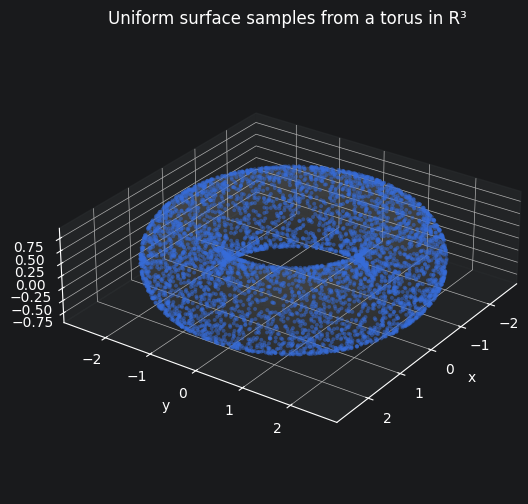

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

rng = np.random.default_rng(42)
n_points = 5_000
major_radius = 2.0
minor_radius = 0.75
assert major_radius > minor_radius > 0.0


def angles_to_torus(angles):
    angles = np.asarray(angles)
    u, v = angles[..., 0], angles[..., 1]
    cylindrical_radius = major_radius + minor_radius * np.cos(v)
    return np.stack((
        cylindrical_radius * np.cos(u),
        cylindrical_radius * np.sin(u),
        minor_radius * np.sin(v),
    ), axis=-1)


def torus_tube_radius(samples):
    samples = np.asarray(samples)
    cylindrical_radius = np.linalg.norm(samples[..., :2], axis=-1)
    return np.sqrt((cylindrical_radius - major_radius)**2 + samples[..., 2]**2)


def sample_uniform_torus(n_samples, rng, batch_size=10_000):
    # dA = r (R + r cos(v)) du dv: uniform angles alone are not area-uniform.
    accepted = []
    n_accepted = 0
    while n_accepted < n_samples:
        candidates = rng.uniform(0.0, 2.0 * np.pi, size=(batch_size, 2))
        acceptance = (
            major_radius + minor_radius * np.cos(candidates[:, 1])
        ) / (major_radius + minor_radius)
        kept = candidates[rng.uniform(size=batch_size) < acceptance]
        accepted.append(kept)
        n_accepted += len(kept)
    angles = np.vstack(accepted)[:n_samples]
    return angles_to_torus(angles), angles


torus_plot_u, torus_plot_v = np.meshgrid(
    np.linspace(0.0, 2.0 * np.pi, 65),
    np.linspace(0.0, 2.0 * np.pi, 33),
)
torus_plot_surface = angles_to_torus(
    np.stack((torus_plot_u, torus_plot_v), axis=-1)
)


def style_torus(axis, extra_points=None):
    axis.plot_surface(
        *torus_plot_surface.transpose(2, 0, 1),
        color="lightgray", alpha=0.12, linewidth=0,
    )
    limits = np.array([
        major_radius + minor_radius + 0.2,
        major_radius + minor_radius + 0.2,
        minor_radius + 0.2,
    ])
    if extra_points is not None:
        limits = np.maximum(limits, np.max(np.abs(extra_points), axis=0) + 0.2)
    axis.set(
        xlim=(-limits[0], limits[0]), ylim=(-limits[1], limits[1]),
        zlim=(-limits[2], limits[2]), xlabel="x", ylabel="y", zlabel="z",
    )
    axis.set_box_aspect(2 * limits)
    axis.view_init(elev=28, azim=35)
    axis.grid(alpha=0.2)


points, construction_angles = sample_uniform_torus(n_points, rng)
np.testing.assert_allclose(torus_tube_radius(points), minor_radius, atol=1e-12)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*points.T, s=8, alpha=0.5, edgecolors="none")
style_torus(ax)
ax.set_title("Uniform surface samples from a torus in R³")
plt.show()

Source / target shapes: (250, 3) (250, 3)
Coordinate dtype: float64
All support pairs: distance <= 3.8209 < cover injectivity bound 4.5118 and azimuth-winding bound 6.0268
Tube-winding squared-length margin >= 0.2705
Every source–target pair has a unique shortest surface geodesic.
Source azimuth: 0.00 degrees; target azimuth: 70.00 degrees; separation: 70.00 degrees
Source tube angle: 90.00 degrees (top); target tube angle: 0.00 degrees (front)
Meridian component of the center angle change: 1.1781
Straight center chord departs from the surface by 0.4567.


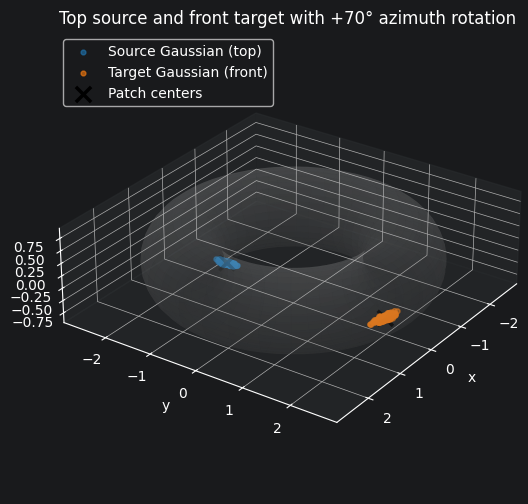

In [38]:
# Keep the top/front tube angles and rotate only the target azimuth by +70°.
rng = np.random.default_rng(123)
angular_variance = 0.04**2
angular_std = np.sqrt(angular_variance)
angle_half_width = 3.0 * angular_std
n_points_per_gaussian = 250
source_major_angle = 0.0
target_major_rotation_degrees = 70.0
source_angle_center = np.array([source_major_angle, np.pi / 2.0])
target_angle_center = np.array([
    source_major_angle + np.deg2rad(target_major_rotation_degrees), 0.0
])
source_center = angles_to_torus(source_angle_center)
target_center = angles_to_torus(target_angle_center)


def sample_angular_gaussian_on_torus(
    mean_angles, angular_std, n_samples, rng,
    half_width=angle_half_width, batch_size=10_000,
):
    mean_angles = np.asarray(mean_angles)
    accepted = []
    n_accepted = 0
    while n_accepted < n_samples:
        candidates = rng.normal(
            loc=mean_angles, scale=angular_std, size=(batch_size, 2)
        )
        kept = candidates[np.all(np.abs(candidates - mean_angles) <= half_width, axis=1)]
        accepted.append(kept)
        n_accepted += len(kept)
    angles = np.vstack(accepted)[:n_samples]
    return angles_to_torus(angles), angles


source_gaussian_points, source_gaussian_angles = sample_angular_gaussian_on_torus(
    source_angle_center, angular_std, n_points_per_gaussian, rng
)
target_gaussian_points, target_gaussian_angles = sample_angular_gaussian_on_torus(
    target_angle_center, angular_std, n_points_per_gaussian, rng
)
gaussian_torus_points = np.vstack((source_gaussian_points, target_gaussian_points))
gaussian_torus_labels = np.repeat([0, 1], n_points_per_gaussian)

# Certify uniqueness for the entire truncated supports.
maximum_angle_difference = (
    np.abs(target_angle_center - source_angle_center) + 2.0 * angle_half_width
)
assert np.all(maximum_angle_difference < np.pi)
assert np.isclose(
    target_angle_center[0] - source_angle_center[0],
    np.deg2rad(target_major_rotation_degrees),
)
assert source_angle_center[1] - angle_half_width > target_angle_center[1] + angle_half_width

maximum_gaussian_curvature = 1.0 / (minor_radius * (major_radius + minor_radius))
cover_injectivity_radius_lower_bound = np.pi / np.sqrt(maximum_gaussian_curvature)

# Auxiliary comparison curves are used only for this geometric certificate;
# kernel fitting, OT, and RFM retain exactly the same methods.
comparison_midpoint_offset = 0.3
source_v_min, source_v_max = source_angle_center[1] + np.array([-1, 1]) * angle_half_width
target_v_min, target_v_max = target_angle_center[1] + np.array([-1, 1]) * angle_half_width
assert target_v_min <= 0.0 < target_v_max < source_v_min < source_v_max < np.pi
assert 2.0 * comparison_midpoint_offset < source_v_min - target_v_max

# Each interval bounds all source tube angles it contains, and all target
# tube angles in [target_v_min, target_v_max].
source_v_edges = np.linspace(source_v_min, source_v_max, 65)
source_v_lower, source_v_upper = source_v_edges[:-1], source_v_edges[1:]
comparison_midpoints = (source_v_lower + target_v_min) / 2.0 + comparison_midpoint_offset
assert np.all((comparison_midpoints > 0.0) & (comparison_midpoints < source_v_lower))


def mean_squared_parallel_radius(v0, v1):
    difference = v0 - v1
    return (
        major_radius**2
        + 2.0 * major_radius * minor_radius * (np.sin(v0) - np.sin(v1)) / difference
        + minor_radius**2 * (
            0.5 + (np.sin(2.0 * v0) - np.sin(2.0 * v1)) / (4.0 * difference)
        )
    )


# Clamp the lower comparison curve at v=0 for a pointwise upper bound on
# (R + r cos(v))**2, then integrate that bound exactly on both linear pieces.
positive_fraction = comparison_midpoints / (comparison_midpoints - target_v_min)
second_half_radius_bound = (
    positive_fraction * mean_squared_parallel_radius(comparison_midpoints, 0.0)
    + (1.0 - positive_fraction) * (major_radius + minor_radius)**2
)
mean_radius_squared_upper = 0.5 * (
    mean_squared_parallel_radius(source_v_lower, comparison_midpoints)
    + second_half_radius_bound
)
tube_difference_upper = source_v_upper - target_v_min
comparison_energy_upper = (
    maximum_angle_difference[0]**2 * mean_radius_squared_upper
    + minor_radius**2 * (tube_difference_upper**2 + 4.0 * comparison_midpoint_offset**2)
)
surface_path_length_upper_bound = np.sqrt(comparison_energy_upper.max())
azimuth_winding_length_lower_bound = (
    (major_radius - minor_radius) * (2.0 * np.pi - maximum_angle_difference[0])
)
# Joint angular lower bounds exclude a competing tube winding even when its
# tube-only length bound is smaller than the global comparison-path bound.
tube_winding_squared_margins = (
    minor_radius**2 * (
        (2.0 * np.pi - tube_difference_upper)**2
        - tube_difference_upper**2 - 4.0 * comparison_midpoint_offset**2
    )
    - (mean_radius_squared_upper - (major_radius - minor_radius)**2)
    * maximum_angle_difference[0]**2
)
tube_winding_squared_margin_lower_bound = tube_winding_squared_margins.min()
assert surface_path_length_upper_bound < cover_injectivity_radius_lower_bound
assert surface_path_length_upper_bound < azimuth_winding_length_lower_bound
assert tube_winding_squared_margin_lower_bound > 0.0
assert np.all(np.abs(source_gaussian_angles - source_angle_center) <= angle_half_width)
assert np.all(np.abs(target_gaussian_angles - target_angle_center) <= angle_half_width)
assert np.all(np.isfinite(gaussian_torus_points))
np.testing.assert_allclose(torus_tube_radius(gaussian_torus_points), minor_radius, atol=1e-12)
print("Source / target shapes:", source_gaussian_points.shape, target_gaussian_points.shape)
print("Coordinate dtype:", gaussian_torus_points.dtype)
print(f"All support pairs: distance <= {surface_path_length_upper_bound:.4f}"
      f" < cover injectivity bound {cover_injectivity_radius_lower_bound:.4f}"
      f" and azimuth-winding bound {azimuth_winding_length_lower_bound:.4f}")
print(f"Tube-winding squared-length margin >= {tube_winding_squared_margin_lower_bound:.4f}")
print("Every source–target pair has a unique shortest surface geodesic.")
center_major_angle_gap = abs(target_angle_center[0] - source_angle_center[0])
center_minor_angle_gap = abs(target_angle_center[1] - source_angle_center[1])
center_tube_arc_component = minor_radius * center_minor_angle_gap
center_chord = np.linspace(source_center, target_center, 101)
center_chord_max_surface_deviation = np.max(
    np.abs(torus_tube_radius(center_chord) - minor_radius)
)
print(f"Source azimuth: {np.degrees(source_angle_center[0]):.2f} degrees;"
      f" target azimuth: {np.degrees(target_angle_center[0]):.2f} degrees;"
      f" separation: {np.degrees(center_major_angle_gap):.2f} degrees")
print(f"Source tube angle: {np.degrees(source_angle_center[1]):.2f} degrees (top);"
      f" target tube angle: {np.degrees(target_angle_center[1]):.2f} degrees (front)")
print(f"Meridian component of the center angle change: {center_tube_arc_component:.4f}")
print(f"Straight center chord departs from the surface by"
      f" {center_chord_max_surface_deviation:.4f}.")

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*source_gaussian_points.T, s=12, alpha=0.6, color="tab:blue", label="Source Gaussian (top)")
ax.scatter(*target_gaussian_points.T, s=12, alpha=0.6, color="tab:orange", label="Target Gaussian (front)")
ax.scatter(*np.vstack((source_center, target_center)).T,
           marker="x", s=120, linewidths=2.5, color="black", label="Patch centers")
style_torus(ax)
ax.set_title("Top source and front target with +70° azimuth rotation")
ax.legend(loc="upper left")
plt.show()

## Construction data for the kernel-profile comparison

The area-uniform torus samples define the shared construction set for all five kernels. The source and target are angular Gaussians truncated to three standard deviations in each angle. Each profile is fitted on the same symmetric CkNN support, then supplies a Laplacian, biharmonic spectral embedding, continuous Nyström extension, and RFM vector field. As in the circle notebook, the comparison evaluates raw and tangent-guarded trajectories and halves the Euler step size.

The embedded torus is
$$T(u,v)=((R+r\cos v)\cos u,\ (R+r\cos v)\sin u,\ r\sin v),\quad R=2,\ r=0.75.$$
Surface-area sampling uses $dA=r(R+r\cos v)\,du\,dv$. The source and target angle centers are $(0,\pi/2)$ and $(70^\circ,0)$, with standard deviation $0.04$ and coordinatewise half-width $h=0.12$. Their tube angles stay at **90° (top source)** and **0° (outer-front target)**. Only the target azimuth changes, by **+70°** around the central hole. The source center remains $(2,0,0.75)$, while the target center is $(2.75\cos70^\circ,2.75\sin70^\circ,0)$.

**Unique shortest paths for the full supports.** Write $a(v)=R+r\cos v$, so the lifted metric on $(u,v)\in\mathbb{R}^2$ is $a(v)^2du^2+r^2dv^2$. Every nonconstant lifted geodesic satisfies Clairaut's relation $a(v)^2\dot u=c$: for $c\ne0$, $u$ is strictly monotone; for $c=0$, $u$ is constant and $v$ is strictly monotone. Thus there are no geodesic loops on this universal cover. Its curvature obeys
$$K(v)=\frac{\cos v}{r(R+r\cos v)}\le K_{\max}=\frac{1}{r(R+r)}.$$
Klingenberg's cut-locus lemma and the conjugate-radius comparison therefore give
$$\operatorname{inj}(\widetilde M)\ge\frac{\pi}{\sqrt{K_{\max}}}
=\pi\sqrt{r(R+r)}\approx4.5118.$$
See [Xu, Klingenberg's lemma](https://arxiv.org/abs/1401.5549) and [Abresch and Meyer, Comparison Geometry](https://library2.msri.org/books/Book30/files/abresch.pdf).

For every source–target pair, the azimuth difference satisfies $0<\delta\le70^\circ+2h\approx1.4617$, and the tube-angle decrease is $d=v_s-v_t\in[\pi/2-2h,\pi/2+2h]$. To obtain a sufficiently tight path bound, consider the auxiliary curve
$$u(t)=u_s+\delta t,\qquad v(t)=(1-t)v_s+tv_t+2b\min(t,1-t),\quad b=0.3.$$
It has the prescribed endpoints and remains between their tube angles. Cauchy–Schwarz bounds its squared length by its energy:
$$L^2\le E=\delta^2 A+r^2(d^2+4b^2),\qquad A=\int_0^1 a(v(t))^2\,dt.$$
The code partitions the source tube-angle support into 64 intervals. Within each interval it uses the smallest source and target tube angles to bound $a(v(t))^2$ from above, clamping the comparison angle at zero where necessary. These piecewise-linear bounds are integrated analytically. Each interval bounds **every point it contains**, with the full target-angle support included.

The resulting uniform comparison-path bound is $U\approx3.8209<\operatorname{inj}(\widetilde M)\approx4.5118$, so the shortest direct-lift geodesic is unique. A nonzero azimuth winding costs at least
$$(R-r)(2\pi-\delta_{\max})\approx6.0268>U.$$
For a nonzero tube winding without azimuth winding, the joint metric lower bound is
$$L_{\mathrm{wrap}}^2\ge(R-r)^2\delta^2+r^2(2\pi-d)^2.$$
For each source interval, let $A_i$ bound $A$ from above and $d_i$ bound $d$ from above. The code checks
$$r^2\!\left[(2\pi-d_i)^2-d_i^2-4b^2\right]
-\left[A_i-(R-r)^2\right]\delta_{\max}^2>0.$$
Its smallest margin is about $0.2705$, so every tube-winding competitor is also strictly longer than a direct-lift comparison path. Thus every pair in the complete truncated supports has a unique shortest surface geodesic, including fresh samples.

The auxiliary curves are used only to certify the dataset placement. Kernel fitting, OT, and RFM retain the same formulas and methods; the approximate biharmonic RFM paths need not coincide with geodesics.

all_generated_points shape: (5500, 3)
construction_points shape: (5000, 3)
construction source: area-uniform torus samples only
source counts:
  uniform torus: 5000
  source Gaussian: 250
  target Gaussian: 250


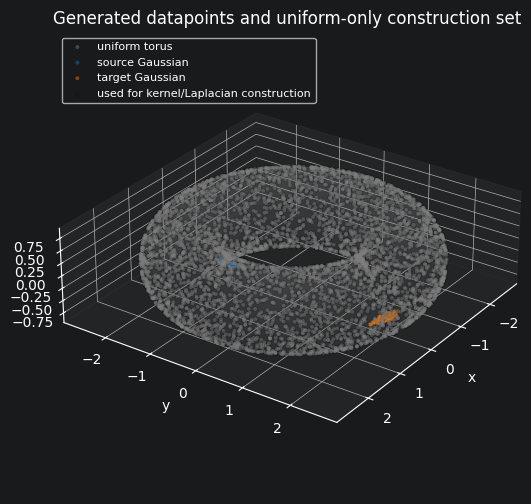

In [39]:
all_generated_points = np.vstack((points, gaussian_torus_points))
construction_points = points.astype(np.float32)
source_labels = np.concatenate((
    np.full(points.shape[0], "uniform torus", dtype=object),
    np.where(gaussian_torus_labels == 0, "source Gaussian", "target Gaussian").astype(object),
))
source_palette = {
    "uniform torus": "tab:gray",
    "source Gaussian": "tab:blue",
    "target Gaussian": "tab:orange",
}
print("all_generated_points shape:", all_generated_points.shape)
print("construction_points shape:", construction_points.shape)
print("construction source: area-uniform torus samples only")
print("source counts:")
for label in source_palette:
    print(f"  {label}: {np.sum(source_labels == label)}")

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, color in source_palette.items():
    cloud = all_generated_points[source_labels == label]
    ax.scatter(*cloud.T, s=8, alpha=0.45, edgecolors="none", color=color, label=label)
ax.scatter(*construction_points.T, s=10, alpha=0.08, color="black",
           label="used for kernel/Laplacian construction")
style_torus(ax)
ax.set_title("Generated datapoints and uniform-only construction set")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### Shared torus projection and tangent helpers

Every profile uses the same torus geometry and probes. For $x=(x_1,x_2,x_3)$, let $\rho=\sqrt{x_1^2+x_2^2}$ and $c(x)=R(x_1/\rho,x_2/\rho,0)$ be its closest major-circle point. Point projection is $P(x)=c(x)+r(x-c(x))/\|x-c(x)\|$, and the unit surface normal is $n=(P(x)-c(x))/r$. The tangent-space guard uses the same expression as the circle example, $v-(v\cdot n)n$. Deterministic fallback directions handle the projection singularities on the axis and major circle.

The torus has no boundary. Raw trajectories evaluate the analytical field directly; guarded trajectories apply this common tangent projection and project after every Euler step. Surface membership is measured by $|\sqrt{(\rho-R)^2+x_3^2}-r|$.

In [4]:
import jax.numpy as jnp
from cellflow.ode_solver._rfm_interpolation import RFMInterpolation


def in_torus(samples, tol=1e-4):
    return np.abs(torus_tube_radius(samples) - minor_radius) <= tol


def project_to_torus(x, eps=1e-12):
    x = jnp.asarray(x)
    cylindrical_radius = jnp.linalg.norm(x[..., :2], axis=-1, keepdims=True)
    fallback_radial = jnp.zeros_like(x[..., :2]).at[..., 0].set(1.0)
    radial = jnp.where(
        cylindrical_radius > eps,
        x[..., :2] / jnp.maximum(cylindrical_radius, eps),
        fallback_radial,
    )
    core = jnp.concatenate((major_radius * radial, jnp.zeros_like(x[..., 2:3])), axis=-1)
    offset = x - core
    offset_norm = jnp.linalg.norm(offset, axis=-1, keepdims=True)
    fallback_normal = jnp.concatenate((radial, jnp.zeros_like(x[..., 2:3])), axis=-1)
    normal = jnp.where(
        offset_norm > eps, offset / jnp.maximum(offset_norm, eps), fallback_normal
    )
    return core + minor_radius * normal


def torus_surface_normal(x):
    y = project_to_torus(x)
    cylindrical_radius = jnp.linalg.norm(y[..., :2], axis=-1, keepdims=True)
    radial = y[..., :2] / cylindrical_radius
    core = jnp.concatenate((major_radius * radial, jnp.zeros_like(y[..., 2:3])), axis=-1)
    return (y - core) / minor_radius


def project_torus_velocity_to_tangent(x, v):
    v = jnp.asarray(v)
    normal = torus_surface_normal(x)
    normal_component = jnp.sum(v * normal, axis=-1, keepdims=True)
    return v - normal_component * normal


class TangentSafeTorusRFMInterpolation(RFMInterpolation):
    def u_t(self, xt, x1, t):
        y = project_to_torus(xt)
        v = super().u_t(y, x1, t)
        return project_torus_velocity_to_tangent(y, v)


def sample_torus_probes(n_major=24, n_minor=8):
    u, v = np.meshgrid(
        np.linspace(0.0, 2.0 * np.pi, n_major, endpoint=False),
        np.linspace(0.0, 2.0 * np.pi, n_minor, endpoint=False),
    )
    angles = np.column_stack((u.ravel(), v.ravel()))
    probe_points = angles_to_torus(angles).astype(np.float32)
    normals = np.column_stack((
        np.cos(v.ravel()) * np.cos(u.ravel()),
        np.cos(v.ravel()) * np.sin(u.ravel()), np.sin(v.ravel()),
    )).astype(np.float32)
    return probe_points, normals


torus_probe_points, torus_probe_normals = sample_torus_probes()

/home/markus/university/adlr/CellFlow/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Symmetric variable-bandwidth kernels: fields and trajectories

This comparison uses the same uniform construction points and CkNN support for every profile:
$\rho_i=\|x_i-x_{i,k_\rho}\|$, $s_{ij}=\|x_i-x_j\|^2/(\delta^2\rho_i\rho_j)$, with edges where $s_{ij}<1$. We compare a fixed-bandwidth Gaussian on this support, a self-tuning Gaussian, $(1-s)_+^4$, a smooth bump, and binary CkNN. Gaussian profiles are truncated here; setting compact_support=False also implements the full Gaussian reference.

| Profile | Weight on a CkNN edge ($s<1$) |
| --- | --- |
| Fixed Gaussian | $\exp(-\|x-y\|^2/(2\sigma^2))$ |
| Variable Gaussian | $\exp(-s/2)$ |
| Compact polynomial | $(1-s)^4$ |
| Smooth bump | $\exp(1-1/(1-s))$ |
| Binary CkNN | $1$ |

The shared support uses kernel_density_k=24 and kernel_delta=2.0. All profiles share construction points, edge candidates, spectral weighting, field probes, starting points, targets, and integration steps. The fixed Gaussian bandwidth is the median positive distance across the 24 non-self nearest neighbors of the construction points. Smooth profiles can lose extremely small weights to underflow; the table reports their retained edges.

By default we use $L=D-W$, matching [Berry and Sauer, Section 6](https://math.gmu.edu/~berry/Publications/CkNN.pdf#page=23). Set kernel_laplacian_type="normalized" to compare the normalized Laplacian. The Nyström formulas, including spectral scales $a_\ell$, are

$$
\Psi_\ell(x)=
\begin{cases}
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}}{d(x)-\lambda_\ell}, & L=D-W,\\[8pt]
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}/\sqrt{d_j}}{\sqrt{d(x)}(1-\lambda_\ell)}, & L=I-D^{-1/2}WD^{-1/2}.
\end{cases}
$$

Analytic gradients differentiate both $d(x)$ and $\rho(x)$. Query scales use the $(k_\rho+1)$th training point, including a possible self-match, so they continuously reproduce the fitted non-self scales at training coordinates. This scale estimator is piecewise smooth at neighbor ties. Normalized graphs retain self-affinities for agreement with the continuous extension; self-affinities cancel from $D-W$.

Binary CkNN has zero extension gradients almost everywhere and therefore produces stationary RFM trajectories. Truncated Gaussians have support-boundary jumps. The polynomial and bump remove those jumps, while retaining possible derivative changes from the bandwidth estimator. Numerical derivative checks and training-coordinate reconstruction are reported before the flow comparison.

In [5]:
import time

import jax
import jax.numpy as jnp
import pandas as pd
from IPython.display import display
from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import eigsh

from cellflow.preprocessing._kernels import SymmetricBandwidthKernel
from cellflow.preprocessing._premetric import (
    SpectralNystroem,
    normalized_laplacian,
    spectral_embedding_scale,
    unnormalized_laplacian,
)

kernel_density_k = 24
kernel_delta = 2.0
kernel_n_modes = 32
kernel_laplacian_type = "unnormalized"
kernel_spectral_weight_type = "biharmonic"
kernel_profiles = {
    "fixed Gaussian": "fixed_gaussian",
    "variable Gaussian": "gaussian",
    "compact polynomial": "polynomial",
    "smooth bump": "bump",
    "binary CkNN": "indicator",
}
kernel_models = {}
kernel_graphs = {}
kernel_fitted = {}
kernel_fit_rows = []

for kernel_name, profile in kernel_profiles.items():
    fit_started = time.perf_counter()
    fitted_kernel = SymmetricBandwidthKernel(
        construction_points,
        profile=profile,
        density_k=kernel_density_k,
        delta=kernel_delta,
    )
    kernel_graph = fitted_kernel.graph(
        include_self=kernel_laplacian_type == "normalized"
    ).astype(np.float64)
    component_count = connected_components(kernel_graph, directed=False)[0]
    if component_count != 1:
        raise ValueError(f"{kernel_name}: {component_count} components; increase density_k or delta.")
    laplacian = (
        unnormalized_laplacian(kernel_graph)
        if kernel_laplacian_type == "unnormalized"
        else normalized_laplacian(kernel_graph)
    )
    eigenvalues, eigenvectors = eigsh(
        laplacian, k=kernel_n_modes + 1, sigma=-1e-8, which="LM", tol=1e-9,
        v0=np.random.default_rng(0).standard_normal(len(construction_points)),
    )
    eigen_order = np.argsort(eigenvalues)
    eigenvalues = eigenvalues[eigen_order][1:]
    eigenvectors = eigenvectors[:, eigen_order][:, 1:]
    component_scales = spectral_embedding_scale(
        eigenvalues, weight_type=kernel_spectral_weight_type
    )
    model = SpectralNystroem(
        construction_points,
        eigenvectors,
        eigenvalues,
        sigma=None,
        psi=eigenvectors * component_scales,
        x_to_id=construction_points,
        graph=kernel_graph,
        kernel=fitted_kernel,
        laplacian_type=kernel_laplacian_type,
        spectral_scale=component_scales,
        target_embedding="nystroem",
    )
    reconstruction_ids = np.linspace(0, len(construction_points) - 1, 20, dtype=int)
    reconstruction = np.asarray(jax.jit(jax.vmap(model.extend_point))(
        jnp.asarray(construction_points[reconstruction_ids])
    ))
    expected_coordinates = np.asarray(model.Psi)[reconstruction_ids]
    reconstruction_error = np.linalg.norm(reconstruction - expected_coordinates) / max(
        np.linalg.norm(expected_coordinates), 1e-12
    )
    kernel_models[kernel_name] = model
    kernel_graphs[kernel_name] = kernel_graph
    kernel_fitted[kernel_name] = fitted_kernel
    degree_values = np.asarray(kernel_graph.sum(axis=1)).ravel()
    kernel_fit_rows.append({
        "kernel": kernel_name,
        "edges": (kernel_graph.nnz - np.count_nonzero(kernel_graph.diagonal())) // 2,
        "components": component_count,
        "min_degree": degree_values.min(),
        "median_degree": np.median(degree_values),
        "lambda_2": eigenvalues[0],
        "max_eigen_residual": np.max(np.linalg.norm(
            laplacian @ eigenvectors - eigenvectors * eigenvalues, axis=0
        )),
        "extension_relative_error": reconstruction_error,
        "fit_seconds": time.perf_counter() - fit_started,
    })
    print(f"{kernel_name}: fitted in {kernel_fit_rows[-1]['fit_seconds']:.2f}s", flush=True)

kernel_fit_df = pd.DataFrame(kernel_fit_rows).set_index("kernel")
kernel_fit_df["retained_edge_fraction"] = (
    kernel_fit_df["edges"] / kernel_fit_df.loc["binary CkNN", "edges"]
)
display(kernel_fit_df)

fixed Gaussian: fitted in 1.87s
variable Gaussian: fitted in 1.31s
compact polynomial: fitted in 1.60s
smooth bump: fitted in 1.42s
binary CkNN: fitted in 1.35s


,edges,components,min_degree,median_degree,lambda_2,max_eigen_residual,extension_relative_error,fit_seconds,retained_edge_fraction
kernel,,,,,,,,,
fixed Gaussian,241976,1,12.870448,23.399877,0.115304,4.335741e-13,9.324539e-08,1.874053,1.000000
variable Gaussian,241976,1,55.469344,75.948436,0.801510,3.221133e-13,1.270467e-07,1.308830,1.000000
compact polynomial,241976,1,14.188333,18.773747,0.070519,1.287147e-13,9.734229e-08,1.595312,1.000000
smooth bump,239079,1,30.002129,38.353600,0.229064,5.053681e-12,1.042600e-07,1.420015,0.988028
binary CkNN,241976,1,69.000000,97.000000,1.111500,4.216158e-13,9.091243e-08,1.352856,1.000000


,median_speed,p95_speed,zero_speed_fraction,unsupported_probe_fraction,normal_velocity_fraction,autodiff_relative_error,finite_difference_relative_error
kernel,,,,,,,
fixed Gaussian,9.639991,56.100266,0.0,0.0,1.0,2.452544e-15,3.537463e-10
variable Gaussian,43.911934,178.681564,0.0,0.0,1.0,8.091833e-15,7.058705e-09
compact polynomial,10.107035,57.411419,0.0,0.0,1.0,4.699310e-15,1.210791e-09
smooth bump,10.439442,48.479675,0.0,0.0,1.0,3.157470e-15,1.206679e-09
binary CkNN,0.000000,0.000000,1.0,0.0,0.0,0.000000e+00,0.000000e+00


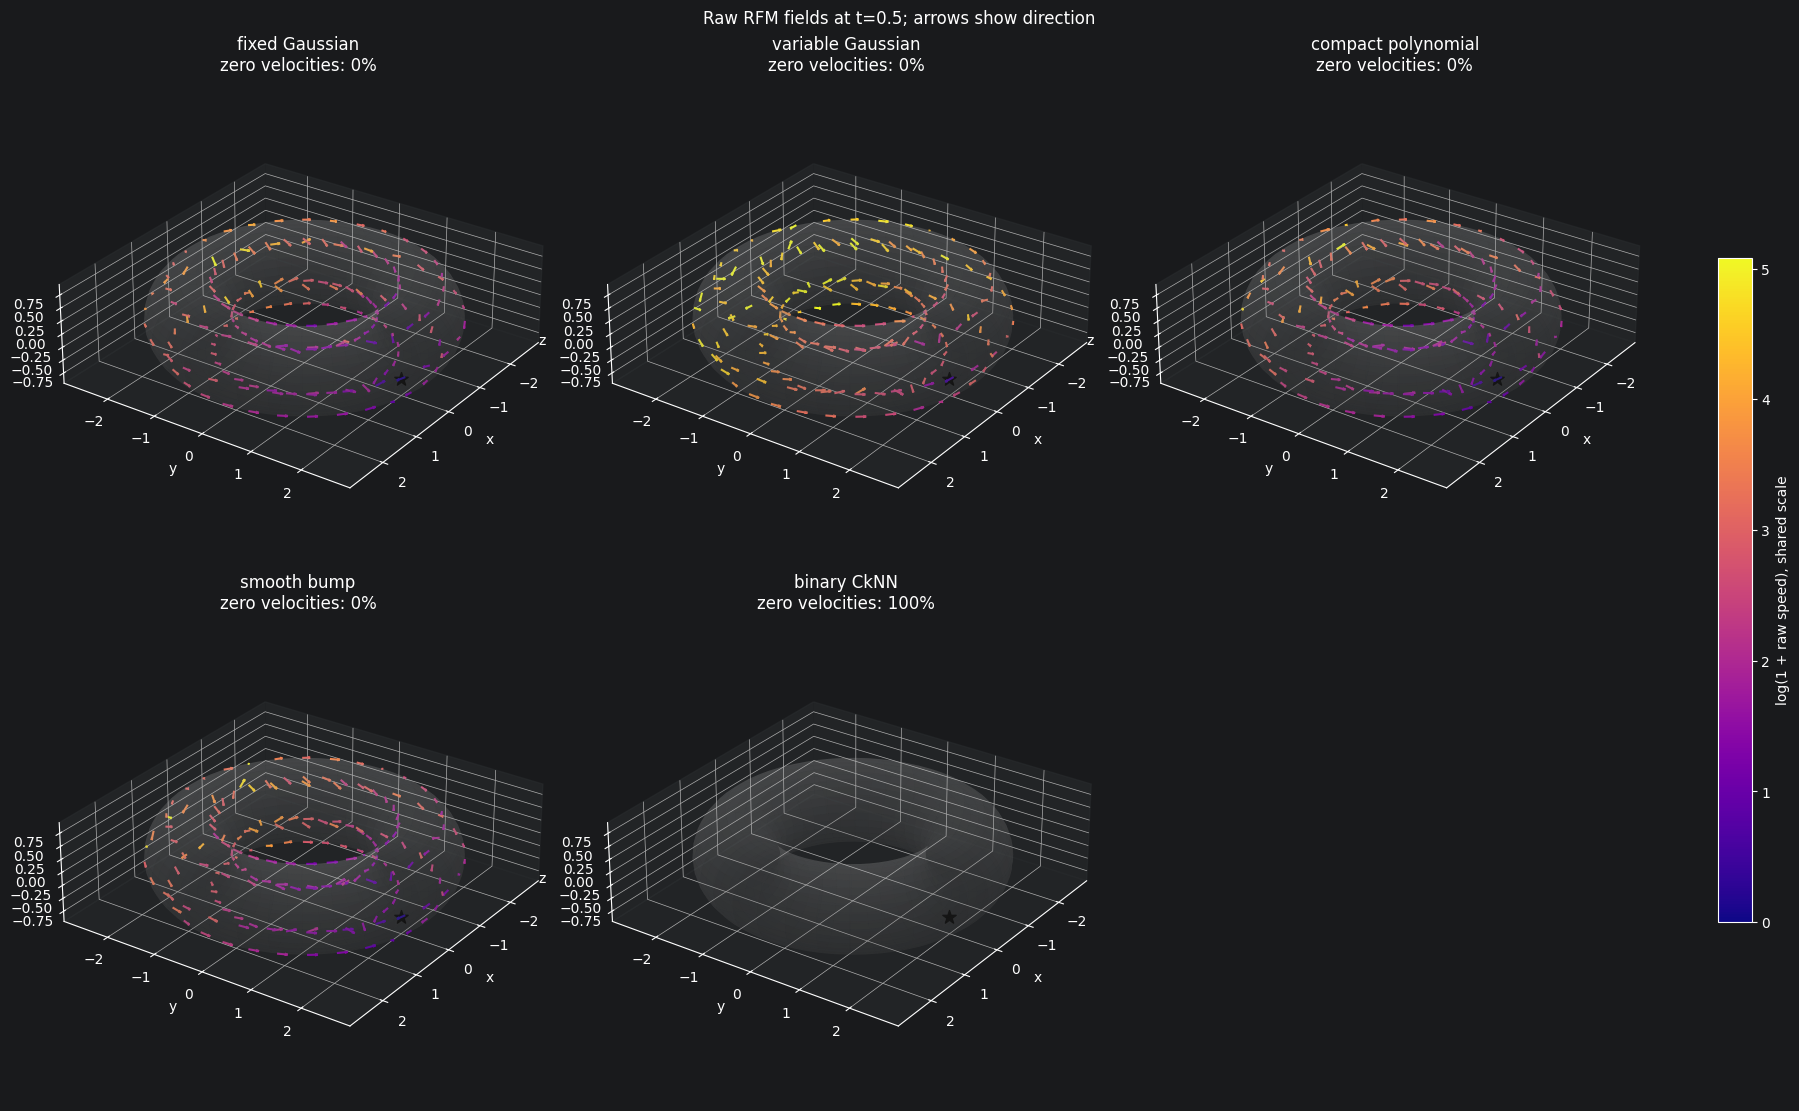

In [40]:
kernel_field_u, kernel_field_v = np.meshgrid(
    np.linspace(0.0, 2.0 * np.pi, 30, endpoint=False),
    np.linspace(0.0, 2.0 * np.pi, 6, endpoint=False),
)
kernel_field_points = angles_to_torus(np.column_stack((
    kernel_field_u.ravel(), kernel_field_v.ravel(),
))).astype(np.float32)
kernel_target = target_center.astype(np.float32)
kernel_field_targets = np.broadcast_to(kernel_target, kernel_field_points.shape)
kernel_field_time = 0.5
kernel_fields = {}
kernel_field_rows = []
kernel_raw_interpolators = {}

for kernel_name, model in kernel_models.items():
    interpolator = RFMInterpolation(model, project_to_manifold=False)
    kernel_raw_interpolators[kernel_name] = interpolator
    velocities = np.asarray(jax.jit(interpolator.u_t)(
        jnp.asarray(kernel_field_points), jnp.asarray(kernel_field_targets), kernel_field_time
    ))
    if not np.all(np.isfinite(velocities)):
        raise ValueError(f"Non-finite vector field for {kernel_name}.")
    speeds = np.linalg.norm(velocities, axis=1)
    support_counts = np.asarray(jax.jit(jax.vmap(
        lambda point: jnp.count_nonzero(kernel_fitted[kernel_name](point))
    ))(jnp.asarray(kernel_field_points)))
    with jax.enable_x64():
        gradient_query = jnp.asarray(angles_to_torus(np.array([0.11, 0.17])), dtype=jnp.float64)
        gradient_target = jnp.asarray(kernel_target, dtype=jnp.float64)

        def checked_distance(point):
            residual = model.extend_point(point) - model.extend_point(gradient_target)
            return jnp.sqrt(jnp.dot(residual, residual) + model.eps)

        _, analytic_gradient, _ = model.distance_grad_and_norm(
            gradient_query, gradient_target
        )
        autodiff_gradient = jax.grad(checked_distance)(gradient_query)
        difference_step = 1e-6
        finite_difference_gradient = np.array([
            (float(checked_distance(gradient_query + direction))
             - float(checked_distance(gradient_query - direction))) / (2.0 * difference_step)
            for direction in np.eye(3) * difference_step
        ])
        gradient_scale = max(float(jnp.linalg.norm(analytic_gradient)), 1e-10)
        autodiff_error = float(jnp.linalg.norm(
            analytic_gradient - autodiff_gradient
        )) / gradient_scale
        finite_difference_error = float(np.linalg.norm(
            np.asarray(analytic_gradient) - finite_difference_gradient
        )) / gradient_scale
    if autodiff_error > 1e-5:
        raise AssertionError(f"{kernel_name}: analytic/autodiff gradient mismatch.")
    probe_velocities = np.asarray(jax.jit(interpolator.u_t)(
        jnp.asarray(torus_probe_points),
        jnp.broadcast_to(jnp.asarray(kernel_target), torus_probe_points.shape),
        kernel_field_time,
    ))
    kernel_fields[kernel_name] = velocities
    kernel_field_rows.append({
        "kernel": kernel_name,
        "median_speed": np.median(speeds),
        "p95_speed": np.quantile(speeds, 0.95),
        "zero_speed_fraction": np.mean(speeds < 1e-8),
        "unsupported_probe_fraction": np.mean(support_counts == 0),
        "normal_velocity_fraction": np.mean(
            np.abs(np.sum(probe_velocities * torus_probe_normals, axis=1)) > 1e-6
        ),
        "autodiff_relative_error": autodiff_error,
        "finite_difference_relative_error": finite_difference_error,
    })

kernel_field_df = pd.DataFrame(kernel_field_rows).set_index("kernel")
display(kernel_field_df)


def style_kernel_torus(axis):
    style_torus(axis)
    axis.scatter(*kernel_target, s=100, marker="*", color="black", zorder=5)


kernel_speed_colors = np.concatenate([
    np.log1p(np.linalg.norm(velocities, axis=1))
    for velocities in kernel_fields.values()
])
kernel_color_max = max(float(np.quantile(kernel_speed_colors, 0.98)), 1e-6)
kernel_color_norm = Normalize(0.0, kernel_color_max)
fig, axes = plt.subplots(
    2, 3, figsize=(18, 11), subplot_kw={"projection": "3d"}, constrained_layout=True
)
for axis, (kernel_name, velocities) in zip(axes.ravel(), kernel_fields.items()):
    speeds = np.linalg.norm(velocities, axis=1)
    directions = 0.18 * velocities / np.maximum(speeds[:, None], 1e-8)
    axis.quiver(
        *kernel_field_points.T, *directions.T,
        colors=plt.get_cmap("plasma")(kernel_color_norm(np.log1p(speeds))),
        length=1.0, normalize=False, arrow_length_ratio=0.3,
    )
    style_kernel_torus(axis)
    axis.set_title(f"{kernel_name}" + chr(10)
                   + f"zero velocities: {np.mean(speeds < 1e-8):.0%}")
for axis in axes.ravel()[len(kernel_fields):]:
    fig.delaxes(axis)
fig.colorbar(
    plt.cm.ScalarMappable(norm=kernel_color_norm, cmap="plasma"),
    ax=list(axes.ravel())[:len(kernel_fields)], label="log(1 + raw speed), shared scale", shrink=0.65,
)
fig.suptitle("Raw RFM fields at t=0.5; arrows show direction")
plt.show()

In [44]:
kernel_start_rng = np.random.default_rng(2026)
kernel_start_ids = kernel_start_rng.choice(len(source_gaussian_points), 12, replace=False)
kernel_starts = source_gaussian_points[kernel_start_ids].astype(np.float32)
kernel_final_time = 0.99
kernel_integration_steps = 800
kernel_step_times = np.linspace(
    0.0, kernel_final_time, kernel_integration_steps + 1, dtype=np.float32
)
kernel_trajectories = {}
kernel_distance_traces = {}
kernel_trajectory_rows = []

def integrate_kernel_paths(model, guarded, steps=None):
    integration_steps = kernel_integration_steps if steps is None else steps
    interpolator = (
        TangentSafeTorusRFMInterpolation(
            model, projection_fn=project_to_torus, project_to_manifold=False
        )
        if guarded else RFMInterpolation(model, project_to_manifold=False)
    )
    targets = jnp.broadcast_to(jnp.asarray(kernel_target), kernel_starts.shape)
    time_step = kernel_final_time / integration_steps
    integration_times = np.linspace(
        0.0, kernel_final_time, integration_steps + 1, dtype=np.float32
    )

    def integrate(starts):
        def step(state, current_time):
            velocities = interpolator.u_t(state, targets, current_time)
            proposed = state + time_step * velocities
            next_state = interpolator.project(proposed)
            return next_state, (next_state, proposed)

        _, (path, proposed_path) = jax.lax.scan(
            step, starts, jnp.asarray(integration_times[:-1])
        )
        return jnp.concatenate((starts[None], path), axis=0), proposed_path

    return jax.jit(integrate)(jnp.asarray(kernel_starts))

def kernel_path_geometry(path):
    segment_starts = path[:-1]
    segments = np.diff(path, axis=0)
    segment_lengths_sq = np.sum(segments**2, axis=-1)
    # Exact minimum cylindrical radius on each straight Euler segment.
    planar_segments = segments[..., :2]
    planar_lengths_sq = np.sum(planar_segments**2, axis=-1)
    closest_fractions = np.clip(
        -np.sum(segment_starts[..., :2] * planar_segments, axis=-1)
        / np.maximum(planar_lengths_sq, 1e-20), 0.0, 1.0
    )
    closest_planar_points = (
        segment_starts[..., :2] + closest_fractions[..., None] * planar_segments
    )
    closest_cylindrical_radii = np.linalg.norm(closest_planar_points, axis=-1)
    # Also inspect the tube surface between projected endpoints.
    fractions = np.linspace(0.0, 1.0, 17)
    segment_probes = (
        segment_starts[..., None, :] + fractions[None, None, :, None] * segments[..., None, :]
    )
    segment_surface_deviation = np.abs(torus_tube_radius(segment_probes) - minor_radius)
    return {
        "max_step_length": np.sqrt(segment_lengths_sq.max()),
        "max_segment_hole_penetration": np.maximum(
            major_radius - minor_radius - closest_cylindrical_radii, 0.0
        ).max(),
        "hole_crossing_segment_fraction": np.mean(
            closest_cylindrical_radii < major_radius - minor_radius - 1e-3
        ),
        "max_domain_violation": np.abs(torus_tube_radius(path) - minor_radius).max(),
        "max_sampled_segment_surface_deviation": segment_surface_deviation.max(),
    }

for kernel_name, model in kernel_models.items():
    for mode, guarded in [("unprojected", False), ("torus + tangent", True)]:
        integration_started = time.perf_counter()
        path, proposed_path = integrate_kernel_paths(model, guarded)
        path = np.asarray(path)
        proposed_path = np.asarray(proposed_path)
        if not np.all(np.isfinite(path)):
            raise ValueError(f"Non-finite trajectories for {kernel_name}, {mode}.")
        sampled_path = path[::8]
        sampled_targets = np.broadcast_to(kernel_target, sampled_path.shape)
        spectral_distances = np.asarray(jax.jit(lambda states: jax.lax.map(
            lambda batch: model.distance_grad_and_norm_batch(
                batch, jnp.asarray(sampled_targets[0])
            )[0], states
        ))(jnp.asarray(sampled_path)))
        violation = np.abs(torus_tube_radius(path) - minor_radius)
        proposed_violation = np.abs(torus_tube_radius(proposed_path) - minor_radius)
        final_errors = np.linalg.norm(path[-1] - kernel_target, axis=1)
        initial_errors = np.linalg.norm(path[0] - kernel_target, axis=1)
        path_lengths = np.linalg.norm(np.diff(path, axis=0), axis=-1).sum(axis=0)
        unsupported_final = np.asarray(jax.jit(jax.vmap(
            lambda point: jnp.count_nonzero(kernel_fitted[kernel_name](point)) == 0
        ))(jnp.asarray(path[-1])))
        kernel_trajectories[kernel_name, mode] = path
        kernel_distance_traces[kernel_name, mode] = spectral_distances
        kernel_trajectory_rows.append({
            "kernel": kernel_name,
            "mode": mode,
            "mean_final_euclidean": np.mean(final_errors),
            "p90_final_euclidean": np.quantile(final_errors, 0.9),
            "mean_relative_euclidean": np.mean(final_errors / initial_errors),
            "fraction_within_0.1": np.mean(final_errors < 0.1),
            "mean_final_relative_spectral": np.mean(
                spectral_distances[-1] / np.maximum(spectral_distances[0], 1e-12)
            ),
            "mean_path_length": np.mean(path_lengths),
            "max_torus_violation": np.max(violation),
            "max_proposed_violation": np.max(proposed_violation),
            "unsupported_final_fraction": np.mean(unsupported_final),
            "integration_seconds": time.perf_counter() - integration_started,
            **kernel_path_geometry(path),
        })
        print(
            f"{kernel_name}, {mode}: mean endpoint error {np.mean(final_errors):.4f}, "
            f"{np.mean(final_errors < 0.1):.0%} within 0.1; "
            f"{kernel_trajectory_rows[-1]['integration_seconds']:.2f}s",
            flush=True,
        )

kernel_trajectory_df = pd.DataFrame(kernel_trajectory_rows)
display(kernel_trajectory_df.sort_values(["mode", "mean_final_euclidean"]).reset_index(drop=True))

fixed Gaussian, unprojected: mean endpoint error 0.0569, 100% within 0.1; 10.83s
fixed Gaussian, torus + tangent: mean endpoint error 0.0247, 100% within 0.1; 15.89s
variable Gaussian, unprojected: mean endpoint error 0.0568, 100% within 0.1; 10.27s
variable Gaussian, torus + tangent: mean endpoint error 0.0076, 100% within 0.1; 11.29s
compact polynomial, unprojected: mean endpoint error 0.0504, 100% within 0.1; 10.33s
compact polynomial, torus + tangent: mean endpoint error 0.0361, 100% within 0.1; 11.78s
smooth bump, unprojected: mean endpoint error 0.0792, 100% within 0.1; 11.73s
smooth bump, torus + tangent: mean endpoint error 0.0337, 100% within 0.1; 12.17s
binary CkNN, unprojected: mean endpoint error 2.8723, 0% within 0.1; 10.21s
binary CkNN, torus + tangent: mean endpoint error 2.8723, 0% within 0.1; 16.54s


,kernel,mode,mean_final_euclidean,p90_final_euclidean,mean_relative_euclidean,fraction_within_0.1,mean_final_relative_spectral,mean_path_length,max_torus_violation,max_proposed_violation,unsupported_final_fraction,integration_seconds,max_step_length,max_segment_hole_penetration,hole_crossing_segment_fraction,max_domain_violation,max_sampled_segment_surface_deviation
0,variable Gaussian,torus + tangent,0.007608,0.009431,0.002649,1.0,0.001004,3.435772,4.172325e-07,1.699328e-04,0.0,11.293016,3.875088e-02,0.0,0.0,4.172325e-07,4.183145e-05
1,fixed Gaussian,torus + tangent,0.024690,0.024951,0.008597,1.0,0.007239,3.351445,4.172325e-07,2.521276e-05,0.0,15.886029,7.262120e-03,0.0,0.0,4.172325e-07,6.248909e-06
2,smooth bump,torus + tangent,0.033732,0.034686,0.011744,1.0,0.009919,3.328764,4.172325e-07,3.862381e-05,0.0,12.167207,8.263921e-03,0.0,0.0,4.172325e-07,9.619161e-06
3,compact polynomial,torus + tangent,0.036122,0.036931,0.012576,1.0,0.009989,3.308884,4.172325e-07,3.284216e-05,0.0,11.783836,7.875462e-03,0.0,0.0,4.172325e-07,8.147383e-06
4,binary CkNN,torus + tangent,2.872260,2.911891,1.000000,0.0,1.000000,0.000013,5.960464e-08,5.960464e-08,0.0,16.538093,1.192093e-07,0.0,0.0,5.960464e-08,9.187735e-08
5,compact polynomial,unprojected,0.050421,0.051802,0.017559,1.0,0.009949,3.262414,3.886449e-02,3.886449e-02,0.0,10.327801,7.899333e-03,0.0,0.0,3.886449e-02,3.886461e-02
6,variable Gaussian,unprojected,0.056808,0.058156,0.019782,1.0,0.005447,3.542637,1.251056e-01,1.251056e-01,0.0,10.269675,3.892078e-02,0.0,0.0,1.251056e-01,1.251057e-01
7,fixed Gaussian,unprojected,0.056857,0.057232,0.019797,1.0,0.007153,3.280308,5.235291e-02,5.235291e-02,0.0,10.830024,7.271884e-03,0.0,0.0,5.235291e-02,5.235293e-02
8,smooth bump,unprojected,0.079168,0.085191,0.027558,1.0,0.009855,3.245840,8.113801e-02,8.113801e-02,0.0,11.734809,8.291846e-03,0.0,0.0,8.113801e-02,8.113829e-02
9,binary CkNN,unprojected,2.872260,2.911891,1.000000,0.0,1.000000,0.000000,5.960464e-08,5.960464e-08,0.0,10.208221,0.000000e+00,0.0,0.0,5.960464e-08,2.730517e-08


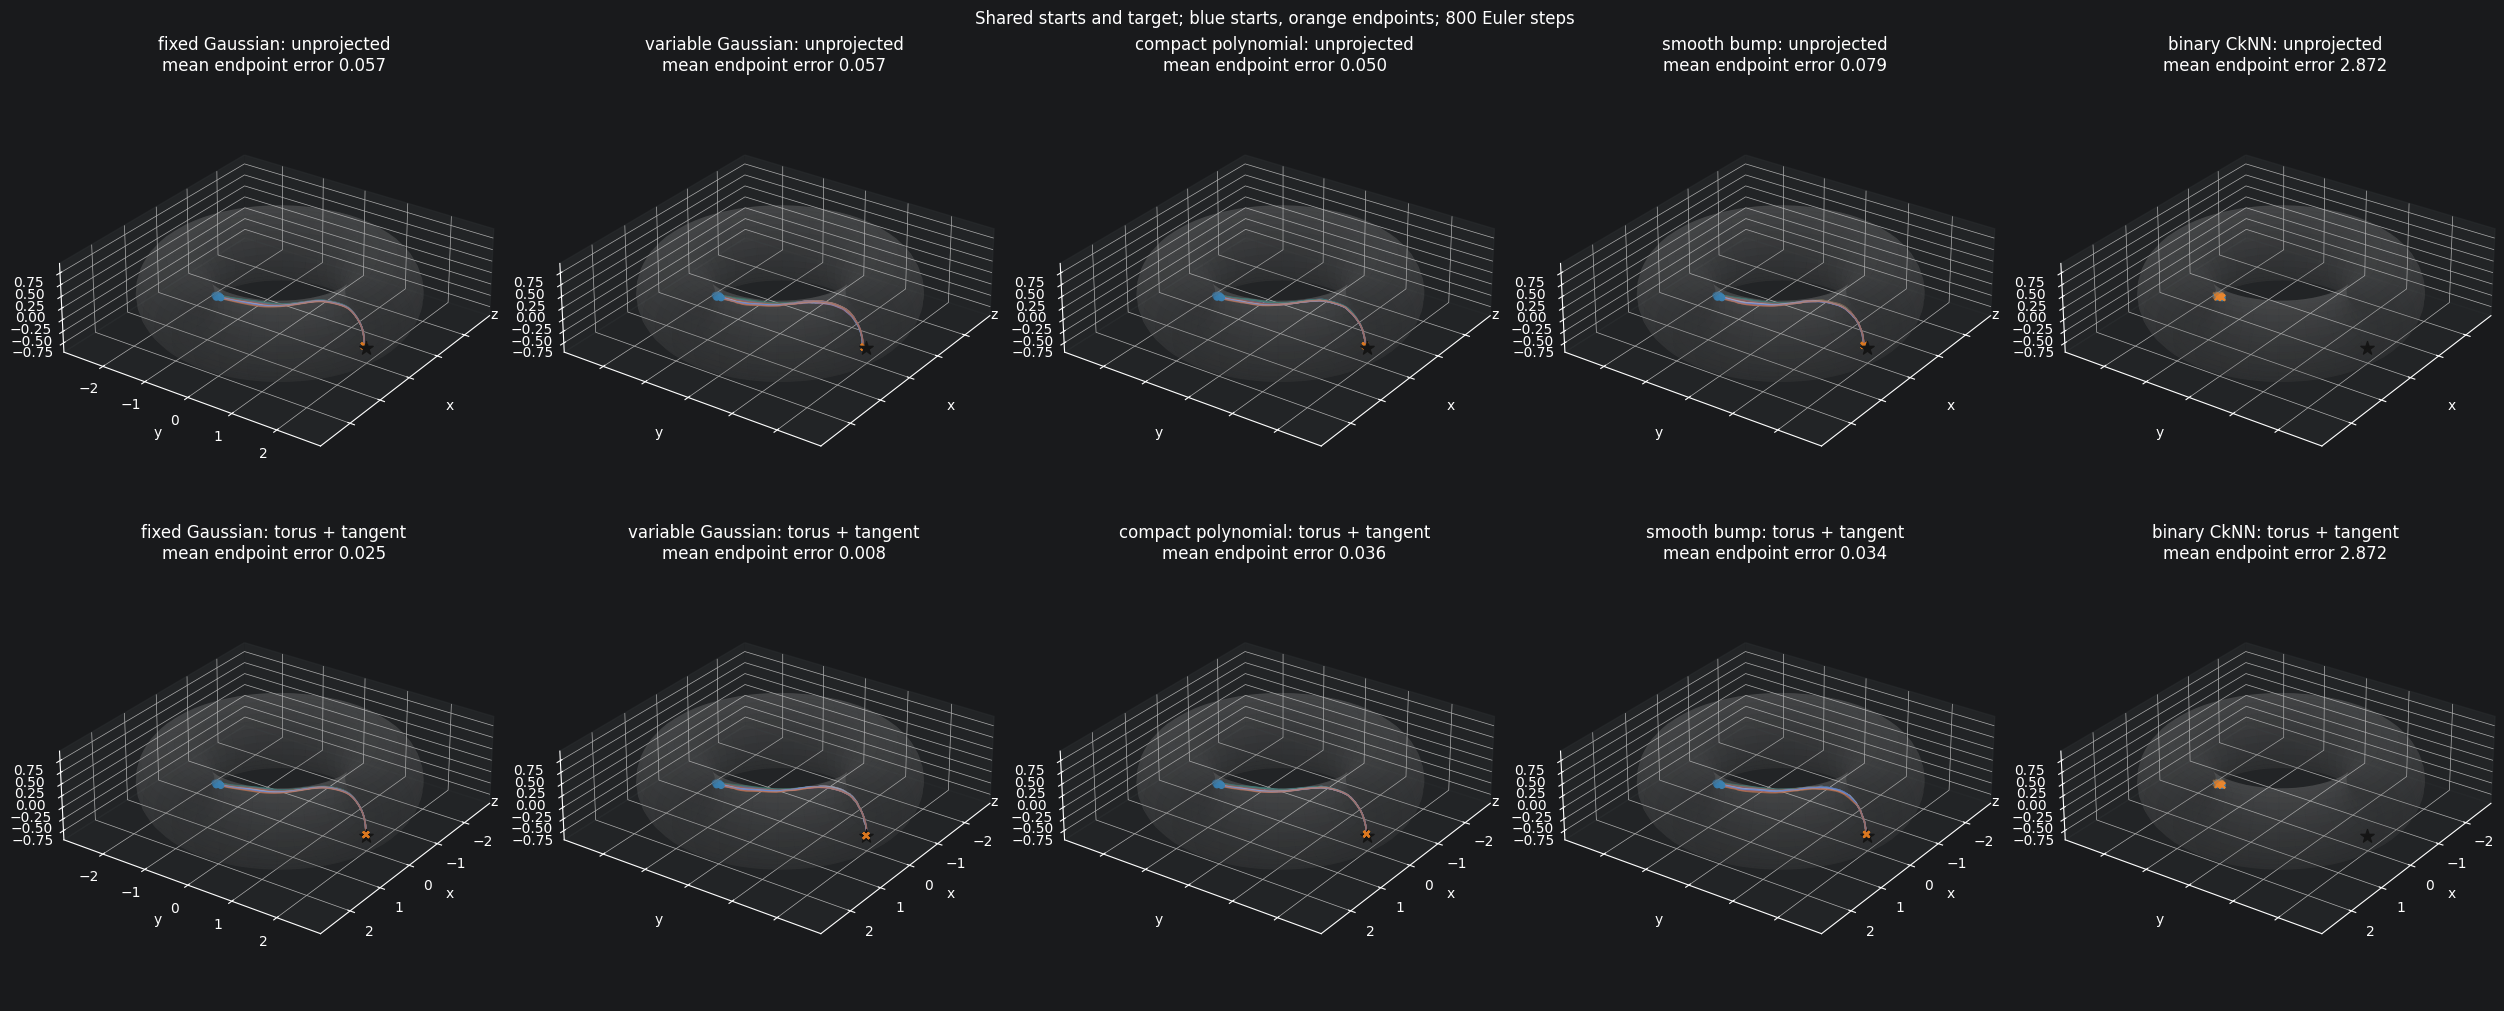

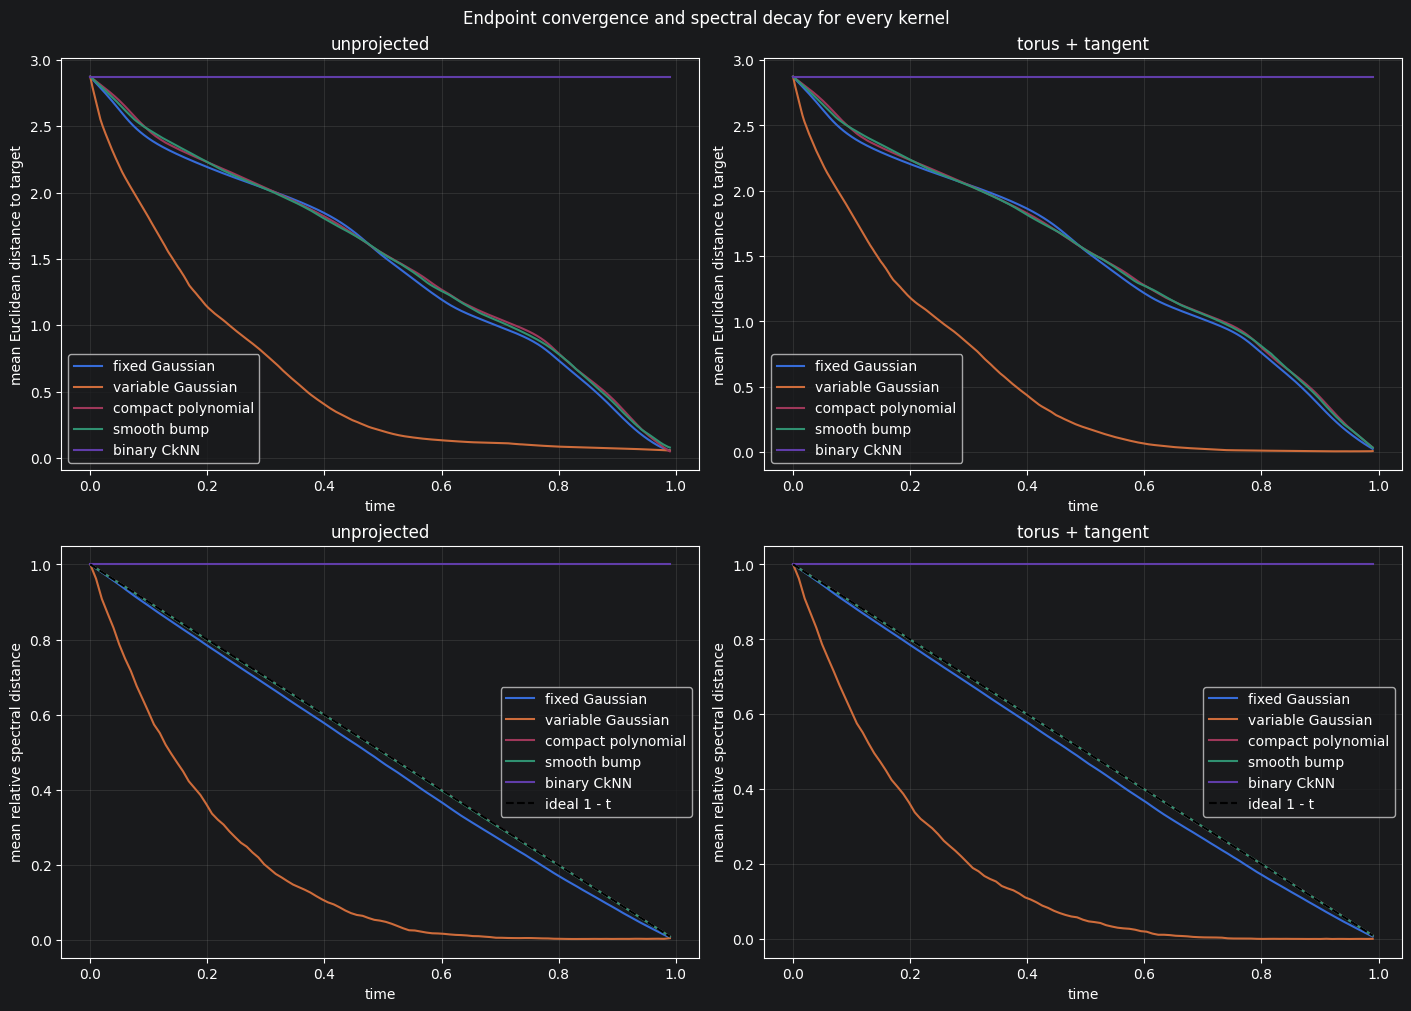

Lowest endpoint error passing domain/segment checks: variable Gaussian (0.0076).
Binary CkNN is a graph baseline: its almost-everywhere zero gradients leave the moving-point interpolation stationary.
Torus projection enforces the domain. Compare the raw normal-field diagnostic and unprojected paths to assess the pre-metric itself.


In [45]:
fig, axes = plt.subplots(
    2, len(kernel_models), figsize=(25, 10), sharex=True, sharey=True,
    constrained_layout=True, subplot_kw={"projection": "3d"},
)
for column, kernel_name in enumerate(kernel_models):
    for row, mode in enumerate(["unprojected", "torus + tangent"]):
        axis = axes[row, column]
        path = kernel_trajectories[kernel_name, mode]
        for start_index in range(len(kernel_starts)):
            axis.plot(*path[:, start_index].T, linewidth=1.1, alpha=0.7)
        axis.scatter(*kernel_starts.T, s=16, color="tab:blue")
        axis.scatter(*path[-1].T, s=18, color="tab:orange", marker="x")
        style_kernel_torus(axis)
        result_row = kernel_trajectory_df[
            kernel_trajectory_df["kernel"].eq(kernel_name)
            & kernel_trajectory_df["mode"].eq(mode)
        ].iloc[0]
        axis.set_title(
            f"{kernel_name}: {mode}\n"
            f"mean endpoint error {result_row['mean_final_euclidean']:.3f}"
        )
fig.suptitle(
    f"Shared starts and target; blue starts, orange endpoints; {kernel_integration_steps} Euler steps"
)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for column, mode in enumerate(["unprojected", "torus + tangent"]):
    for kernel_name in kernel_models:
        path = kernel_trajectories[kernel_name, mode]
        ambient_errors = np.linalg.norm(path - kernel_target, axis=-1)
        axes[0, column].plot(
            kernel_step_times, ambient_errors.mean(axis=1), label=kernel_name
        )
        distances = kernel_distance_traces[kernel_name, mode]
        axes[1, column].plot(
            kernel_step_times[::8],
            (distances / np.maximum(distances[0], 1e-12)).mean(axis=1),
            label=kernel_name,
        )
    axes[0, column].set(
        title=mode, xlabel="time", ylabel="mean Euclidean distance to target"
    )
    axes[1, column].plot(
        kernel_step_times, 1.0 - kernel_step_times, "k--", label="ideal 1 - t"
    )
    axes[1, column].set(
        title=mode, xlabel="time", ylabel="mean relative spectral distance"
    )
    axes[0, column].legend()
    axes[1, column].legend()
    axes[0, column].grid(alpha=0.2)
    axes[1, column].grid(alpha=0.2)
fig.suptitle("Endpoint convergence and spectral decay for every kernel")
plt.show()

guarded_kernel_results = kernel_trajectory_df[
    kernel_trajectory_df["mode"].eq("torus + tangent")
].sort_values("mean_final_euclidean")
valid_guarded_results = guarded_kernel_results[
    guarded_kernel_results["max_segment_hole_penetration"].le(1e-3)
    & guarded_kernel_results["max_domain_violation"].le(1e-3)
    & guarded_kernel_results["max_sampled_segment_surface_deviation"].le(1e-3)
    & guarded_kernel_results["unsupported_final_fraction"].eq(0.0)
]
if len(valid_guarded_results):
    best_kernel_result = valid_guarded_results.iloc[0]
    print(
        f"Lowest endpoint error passing domain/segment checks: {best_kernel_result['kernel']} "
        f"({best_kernel_result['mean_final_euclidean']:.4f})."
    )
print(
    "Binary CkNN is a graph baseline: its almost-everywhere zero gradients "
    "leave the moving-point interpolation stationary."
)
print(
    "Torus projection enforces the domain. Compare the raw normal-field "
    "diagnostic and unprojected paths to assess the pre-metric itself."
)

fixed Gaussian, 1600 guarded steps: mean endpoint error 0.0248; maximum hole penetration 0.0000
variable Gaussian, 1600 guarded steps: mean endpoint error 0.0060; maximum hole penetration 0.0000
compact polynomial, 1600 guarded steps: mean endpoint error 0.0361; maximum hole penetration 0.0000
smooth bump, 1600 guarded steps: mean endpoint error 0.0339; maximum hole penetration 0.0000
binary CkNN, 1600 guarded steps: mean endpoint error 2.8723; maximum hole penetration 0.0000


,coarse_mean_endpoint_error,refined_mean_endpoint_error,mean_endpoint_shift,refined_fraction_within_0.1,passes_domain_segment_checks,max_step_length,max_segment_hole_penetration,hole_crossing_segment_fraction,max_domain_violation,max_sampled_segment_surface_deviation,refinement_seconds
kernel,,,,,,,,,,,
fixed Gaussian,0.024690,0.024809,1.280578e-04,1.0,True,3.656375e-03,0.0,0.0,4.172325e-07,1.690854e-06,30.670594
variable Gaussian,0.007608,0.005980,2.053600e-03,1.0,True,1.897634e-02,0.0,0.0,4.768372e-07,1.292319e-05,21.871387
compact polynomial,0.036122,0.036099,2.556494e-04,1.0,True,3.969599e-03,0.0,0.0,4.172325e-07,2.034210e-06,20.721688
smooth bump,0.033732,0.033923,7.757079e-04,1.0,True,4.131912e-03,0.0,0.0,4.172325e-07,2.440914e-06,20.959005
binary CkNN,2.872260,2.872260,9.934108e-09,0.0,True,1.192093e-07,0.0,0.0,5.960464e-08,9.187735e-08,28.614597


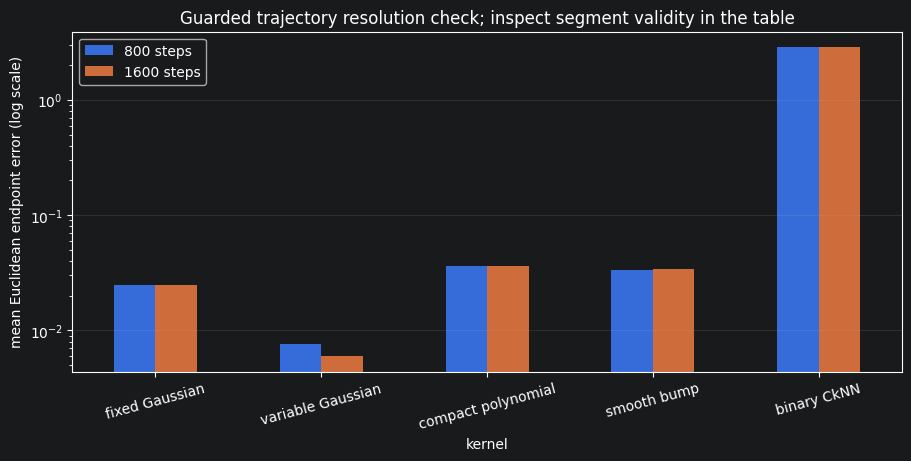

In [46]:
kernel_refinement_steps = 2 * kernel_integration_steps
kernel_refinement_rows = []
kernel_refined_trajectories = {}

for kernel_name, model in kernel_models.items():
    refinement_started = time.perf_counter()
    refined_path, _ = integrate_kernel_paths(
        model, guarded=True, steps=kernel_refinement_steps
    )
    refined_path = np.asarray(refined_path)
    if not np.all(np.isfinite(refined_path)):
        raise ValueError(f"{kernel_name}: non-finite refined trajectories.")
    refined_errors = np.linalg.norm(refined_path[-1] - kernel_target, axis=1)
    coarse_path = kernel_trajectories[kernel_name, "torus + tangent"]
    coarse_errors = np.linalg.norm(coarse_path[-1] - kernel_target, axis=1)
    geometry = kernel_path_geometry(refined_path)
    kernel_refined_trajectories[kernel_name] = refined_path
    kernel_refinement_rows.append({
        "kernel": kernel_name,
        "coarse_mean_endpoint_error": np.mean(coarse_errors),
        "refined_mean_endpoint_error": np.mean(refined_errors),
        "mean_endpoint_shift": np.linalg.norm(
            refined_path[-1] - coarse_path[-1], axis=1
        ).mean(),
        "refined_fraction_within_0.1": np.mean(refined_errors < 0.1),
        "passes_domain_segment_checks": (
            geometry["max_domain_violation"] <= 1e-3
            and geometry["max_segment_hole_penetration"] <= 1e-3
            and geometry["max_sampled_segment_surface_deviation"] <= 1e-3
        ),
        **geometry,
        "refinement_seconds": time.perf_counter() - refinement_started,
    })
    print(
        f"{kernel_name}, {kernel_refinement_steps} guarded steps: "
        f"mean endpoint error {np.mean(refined_errors):.4f}; "
        f"maximum hole penetration {geometry['max_segment_hole_penetration']:.4f}",
        flush=True,
    )

kernel_refinement_df = pd.DataFrame(kernel_refinement_rows).set_index("kernel")
display(kernel_refinement_df)

fig, axis = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
kernel_error_comparison = kernel_refinement_df[[
    "coarse_mean_endpoint_error", "refined_mean_endpoint_error"
]].rename(columns={
    "coarse_mean_endpoint_error": f"{kernel_integration_steps} steps",
    "refined_mean_endpoint_error": f"{kernel_refinement_steps} steps",
})
kernel_error_comparison.plot.bar(ax=axis, rot=15, logy=True)
axis.set_ylabel("mean Euclidean endpoint error (log scale)")
axis.set_title("Guarded trajectory resolution check; inspect segment validity in the table")
axis.grid(axis="y", alpha=0.2)
plt.show()

The fields use a shared color scale and direction-normalized arrows. The two trajectory rows separate the raw field from a common torus projection and tangent-space guard. Projection can keep a poor field on the torus, so read endpoint errors together with the raw normal-velocity diagnostic and unprojected paths. Unsupported queries are reported explicitly.

For each straight Euler segment, the geometry checks compute the exact minimum cylindrical radius to detect crossings of the central hole. They also sample 17 locations per segment to report surface deviation between endpoints; this sampled value is not a rigorous continuous maximum. The acceptance tolerance is $10^{-3}$. Compare coarse and refined runs before interpreting a small endpoint error as convergence of the field ODE.

Raw spectral distances have different scales across profiles; the decay plot normalizes each path by its own initial distance. Euclidean endpoint error compares target convergence in common ambient coordinates. These are deterministic toy comparisons on area-uniform construction points, not a density-robustness benchmark.

The fitted extensions, kernels, graphs, trajectories, and refinement results are available in kernel_models, kernel_fitted, kernel_graphs, kernel_trajectories, and kernel_refinement_df.

## Train CellFlow RFM between the two Gaussian clouds

The source Gaussian is the source/control distribution and the target Gaussian is the target. The selected model from `kernel_models` supplies the same biharmonic geometry to OT matching and RFM interpolation:

$$c(x,y)=d_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2,\qquad \Psi_k(x)=\phi_k(x)/(\lambda_k+10^{-8}).$$

`match_biharmonic` evaluates the continuous Nyström embedding and calls the existing `cellflow.utils.match_linear` with the **unsquared** embedding distance. The standard `CellFlow(..., solver="otrfm") → prepare_data → prepare_model → train → predict` workflow keeps all cell coordinates three-dimensional and samples pairs from the OT coupling on each training batch. This is a linear OT problem with a manifold-aware cost.

Run the data-generation, construction, torus-helper, and kernel-fit cells above first. The kernel comparison plots are optional. The compact network and training settings below suit this toy example. OT uses mean cost scaling, so `rfm_ot_epsilon` is relative to the batch's mean biharmonic cost. Training interpolation projects to the torus; standard model prediction is unconstrained, and the evaluation reports its domain violations. Evaluation uses the fitted clouds and measures reconstruction, not generalization.

In [48]:
import anndata as ad
import optax
from ott.geometry import costs
from scipy.spatial.distance import cdist

from cellflow.model import CellFlow
from cellflow.utils import match_linear

rfm_kernel_name = "fixed Gaussian"
rfm_nystroem = kernel_models[rfm_kernel_name]
rfm_ot_epsilon = 0.05
rfm_batch_size = 32
rfm_interpolation_steps = 32
rfm_num_iterations = 300
rfm_seed = 2026

rfm_source = source_gaussian_points.astype(np.float32)
rfm_target = target_gaussian_points.astype(np.float32)
assert kernel_spectral_weight_type == "biharmonic"
assert rfm_source.shape[1] == rfm_target.shape[1] == 3
assert np.all(np.isfinite(rfm_source)) and np.all(np.isfinite(rfm_target))
assert np.all(in_torus(rfm_source)) and np.all(in_torus(rfm_target))

# Embed each batch once, then let OTT form its pairwise cost matrix.
# Euclidean distance in these weighted coordinates IS biharmonic distance.
rfm_embed = jax.jit(jax.vmap(rfm_nystroem.extend_point))


def match_biharmonic(source_batch, target_batch):
    return match_linear(
        rfm_embed(jnp.asarray(source_batch)),
        rfm_embed(jnp.asarray(target_batch)),
        cost_fn=costs.Euclidean(),
        epsilon=rfm_ot_epsilon,
        scale_cost="mean",
        tau_a=1.0,
        tau_b=1.0,
        threshold=1e-5,
        max_iterations=5000,
    )


rfm_match_jit = jax.jit(match_biharmonic)
print(f"Geometry: {rfm_kernel_name}, {rfm_nystroem.Psi.shape[1]} biharmonic modes")
print(f"Source: {rfm_source.shape}; target: {rfm_target.shape}")
print(f"Batch size: {rfm_batch_size}; interpolation steps: {rfm_interpolation_steps}")
print(f"OT cost: unsquared biharmonic distance; relative epsilon: {rfm_ot_epsilon}")

Geometry: fixed Gaussian, 32 biharmonic modes
Source: (250, 3); target: (250, 3)
Batch size: 32; interpolation steps: 32
OT cost: unsquared biharmonic distance; relative epsilon: 0.05


,coupling diagnostics
coupling_mass,9.999994e-01
max_source_marginal_error,4.656613e-09
max_target_marginal_error,6.519258e-09
OT_mean_biharmonic_cost,2.357982e-01
independent_mean_biharmonic_cost,2.357988e-01


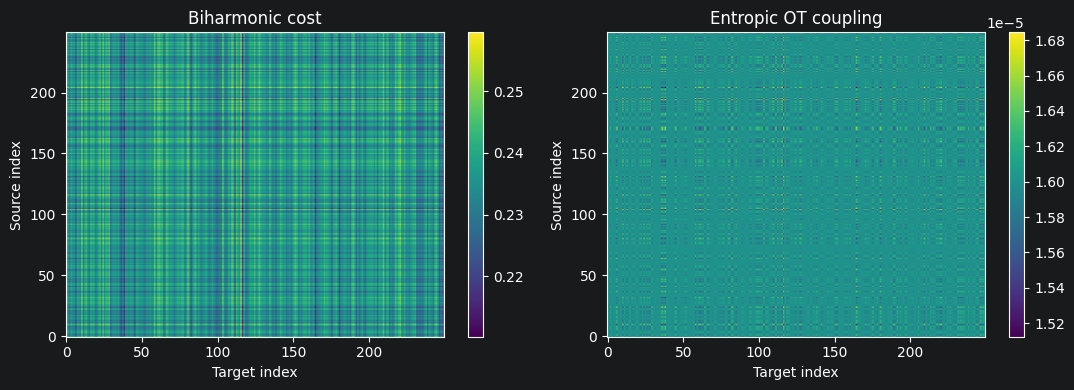

In [49]:
# Full-cloud diagnostic; training recomputes the coupling for each sampled batch.
rfm_source_embedding = np.asarray(rfm_embed(jnp.asarray(rfm_source)))
rfm_target_embedding = np.asarray(rfm_embed(jnp.asarray(rfm_target)))
rfm_cost_matrix = cdist(rfm_source_embedding, rfm_target_embedding)
rfm_coupling = np.asarray(rfm_match_jit(rfm_source, rfm_target))

assert rfm_coupling.shape == (len(rfm_source), len(rfm_target))
assert np.all(np.isfinite(rfm_coupling)) and np.all(rfm_coupling >= 0)
np.testing.assert_allclose(rfm_coupling.sum(axis=1), 1 / len(rfm_source), atol=5e-5)
np.testing.assert_allclose(rfm_coupling.sum(axis=0), 1 / len(rfm_target), atol=5e-5)

# Check that the OT cost agrees with the distance used by RFM.
rfm_check_distances = np.asarray(jax.jit(
    rfm_nystroem.distance_grad_and_norm_batch
)(jnp.asarray(rfm_source[:8]), jnp.asarray(rfm_target[:8]))[0])
np.testing.assert_allclose(
    np.diag(rfm_cost_matrix[:8, :8]), rfm_check_distances, rtol=1e-5, atol=1e-6
)
# A reordered, rectangular batch also works without global point indices.
rfm_rectangular_coupling = np.asarray(
    rfm_match_jit(rfm_source[7:0:-1], rfm_target[2:11])
)
assert rfm_rectangular_coupling.shape == (7, 9)
assert np.all(np.isfinite(rfm_rectangular_coupling))

display(pd.DataFrame({
    "coupling_mass": rfm_coupling.sum(),
    "max_source_marginal_error": np.max(np.abs(rfm_coupling.sum(axis=1) - 1 / len(rfm_source))),
    "max_target_marginal_error": np.max(np.abs(rfm_coupling.sum(axis=0) - 1 / len(rfm_target))),
    "OT_mean_biharmonic_cost": np.sum(rfm_coupling * rfm_cost_matrix),
    "independent_mean_biharmonic_cost": rfm_cost_matrix.mean(),
}, index=["coupling diagnostics"]).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in [
    (axes[0], rfm_cost_matrix, "Biharmonic cost"),
    (axes[1], rfm_coupling, "Entropic OT coupling"),
]:
    image = ax.imshow(values, aspect="auto", origin="lower")
    ax.set(xlabel="Target index", ylabel="Source index", title=title)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [50]:
# AnnData contains only the two Gaussian clouds; the uniform torus is geometry.
rfm_n_source = len(rfm_source)
rfm_adata = ad.AnnData(
    X=np.vstack((rfm_source, rfm_target)),
    obs=pd.DataFrame(
        {
            "control": np.r_[np.ones(rfm_n_source, dtype=bool), np.zeros(len(rfm_target), dtype=bool)],
            "target_gaussian": np.r_[np.zeros(rfm_n_source, dtype=bool), np.ones(len(rfm_target), dtype=bool)],
        },
        index=[f"toy_{i}" for i in range(rfm_n_source + len(rfm_target))],
    ),
)

rfm_cf = CellFlow(rfm_adata, solver="otrfm")
rfm_cf.prepare_data(
    sample_rep="X",
    control_key="control",
    perturbation_covariates={"transport": ["target_gaussian"]},
)
rfm_cf.prepare_model(
    match_fn=match_biharmonic,
    nystroem=rfm_nystroem,
    condition_mode="deterministic",
    pooling="mean",
    layers_before_pool=[],
    layers_after_pool=[],
    condition_embedding_dim=16,
    cond_output_dropout=0.0,
    time_freqs=16,
    time_encoder_dims=(32, 32),
    hidden_dims=(64, 64),
    decoder_dims=(64, 64),
    conditioning_kwargs={},
    optimizer=optax.adam(1e-3),
    solver_kwargs={
        "interpolation_steps": rfm_interpolation_steps,
        "projection_fn": project_to_torus,
        "project_to_manifold": False,
        "max_velocity_norm": 30.0,
    },
    seed=rfm_seed,
)

# The default dataloader must see the top patch as source and the front patch as target.
from cellflow.data._dataloader import TrainSampler

rfm_probe_batch = TrainSampler(rfm_cf.train_data, batch_size=rfm_batch_size).sample(
    np.random.default_rng(rfm_seed)
)
assert np.all(np.asarray(rfm_probe_batch["src_cell_data"])[:, 2] > minor_radius / 2.0)
assert np.all(np.abs(np.asarray(rfm_probe_batch["tgt_cell_data"])[:, 2]) < minor_radius / 2.0)
print("Solver:", type(rfm_cf.solver).__name__)
print("Coordinate dimensions:", rfm_cf.train_data.cell_data.shape[1])
print("Conditions:", rfm_cf.train_data.condition_data)

[########################################] | 100% Completed | 101.78 ms
[########################################] | 100% Completed | 102.33 ms
Solver: OTRFlowMatching
Coordinate dimensions: 3
Conditions: {'transport': array([[[1.]]])}


In [51]:
# Baseline: leave the source cloud unchanged.
# These empirical distribution metrics do not assume pointwise correspondences.
def rfm_distribution_metrics(samples):
    samples = np.asarray(samples)
    energy = (
        2 * cdist(samples, rfm_target).mean()
        - cdist(samples, samples).mean()
        - cdist(rfm_target, rfm_target).mean()
    )
    return {
        "energy_distance_squared": float(max(energy, 0.0)),
        "mean_error_to_target": float(np.linalg.norm(samples.mean(axis=0) - rfm_target.mean(axis=0))),
        "outside_torus_fraction": float(np.mean(~in_torus(samples))),
    }


rfm_baseline_metrics = rfm_distribution_metrics(rfm_source)
print("Unchanged-source baseline:", rfm_baseline_metrics, flush=True)
rfm_training_started = time.perf_counter()
rfm_cf.train(
    num_iterations=rfm_num_iterations,
    batch_size=rfm_batch_size,
    valid_freq=100,
)
rfm_training_seconds = time.perf_counter() - rfm_training_started
rfm_losses = np.asarray(rfm_cf.trainer.training_logs["loss"])
assert len(rfm_losses) == rfm_num_iterations and np.all(np.isfinite(rfm_losses))
assert rfm_cf.solver.is_trained
print(f"Training finished in {rfm_training_seconds:.1f}s", flush=True)
print(f"Mean loss, first 25: {rfm_losses[:25].mean():.5f}; last 25: {rfm_losses[-25:].mean():.5f}")

Unchanged-source baseline: {'energy_distance_squared': 5.541736918097798, 'mean_error_to_target': 2.887708902359009, 'outside_torus_fraction': 0.0}


100%|██████████| 300/300 [04:30<00:00,  1.11it/s, loss=0.698]

Training finished in 270.1s
Mean loss, first 25: 2.49802; last 25: 0.28527


[########################################] | 100% Completed | 102.34 ms
[########################################] | 100% Completed | 100.79 ms


,energy_distance_squared,mean_error_to_target,outside_torus_fraction
unchanged source,5.541737,2.887709,0.0
trained RFM prediction,0.112643,0.107828,1.0


Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.


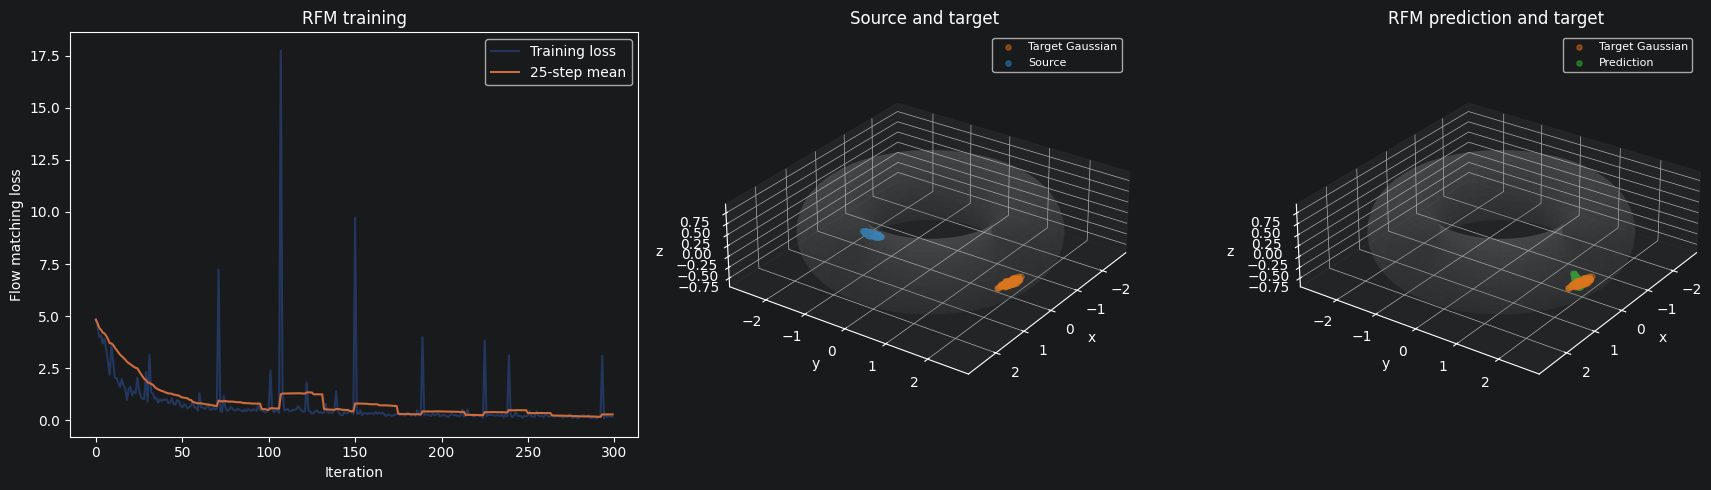

In [52]:
# Use the public prediction API on the source/control cloud.
rfm_source_adata = rfm_adata[rfm_adata.obs["control"]].copy()
rfm_predictions = rfm_cf.predict(
    rfm_source_adata,
    covariate_data=pd.DataFrame({"control": [True], "target_gaussian": [True], "condition": ["target Gaussian"]}),
    condition_id_key="condition",
)
rfm_predicted = np.asarray(rfm_predictions["target Gaussian"])
assert rfm_predicted.shape == rfm_source.shape
assert np.all(np.isfinite(rfm_predicted))
rfm_evaluation = pd.DataFrame(
    [rfm_baseline_metrics, rfm_distribution_metrics(rfm_predicted)],
    index=["unchanged source", "trained RFM prediction"],
)
display(rfm_evaluation)
print("Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.")


fig = plt.figure(figsize=(18, 5))
axes = [
    fig.add_subplot(131),
    fig.add_subplot(132, projection="3d"),
    fig.add_subplot(133, projection="3d"),
]
axes[0].plot(rfm_losses, alpha=0.35, label="Training loss")
rfm_smooth_loss = pd.Series(rfm_losses).rolling(25, min_periods=1).mean()
axes[0].plot(rfm_smooth_loss, label="25-step mean")
axes[0].set(xlabel="Iteration", ylabel="Flow matching loss", title="RFM training")
axes[0].legend()
for ax, cloud, title, color in [
    (axes[1], rfm_source, "Source and target", "tab:blue"),
    (axes[2], rfm_predicted, "RFM prediction and target", "tab:green"),
]:
    ax.scatter(*rfm_target.T, s=14, alpha=0.4, color="tab:orange", label="Target Gaussian")
    ax.scatter(*cloud.T, s=14, alpha=0.6, color=color,
               label="Source" if ax is axes[1] else "Prediction")
    style_torus(ax, extra_points=cloud)
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Reading the training result

The coupling checks verify balanced marginals and agreement between the OT cost and the RFM biharmonic distance. The prediction table compares empirical distributions without assuming a pointwise pairing between the two clouds.

The public `predict` method integrates the learned field with its standard unconstrained ODE solver; `projection_fn` in `solver_kwargs` only projects the training interpolations. Read the distribution metrics together with the fraction of predicted endpoints off the torus. The displayed metrics and plots should be checked again whenever the kernel, regularization, interpolation resolution, or training length changes.

## Inspect the learned vector field at a point and time

Set `rfm_query_point` to the current position $x_t\in\mathbb{R}^3$ and `rfm_field_time` to a time in $[0,1]$, then rerun the cell below. It evaluates $v_\theta(t,x_t\mid\mathrm{target\ Gaussian})$ using the trained inference weights, the same condition as prediction, and dropout disabled.

The colored arrows show the learned field on a torus grid; the red arrow highlights the selected point. Colors encode speed. All arrow lengths equal `arrow_dt` times velocity, so their magnitudes remain comparable. These are instantaneous velocities. The plot uses the field directly, including normal components.

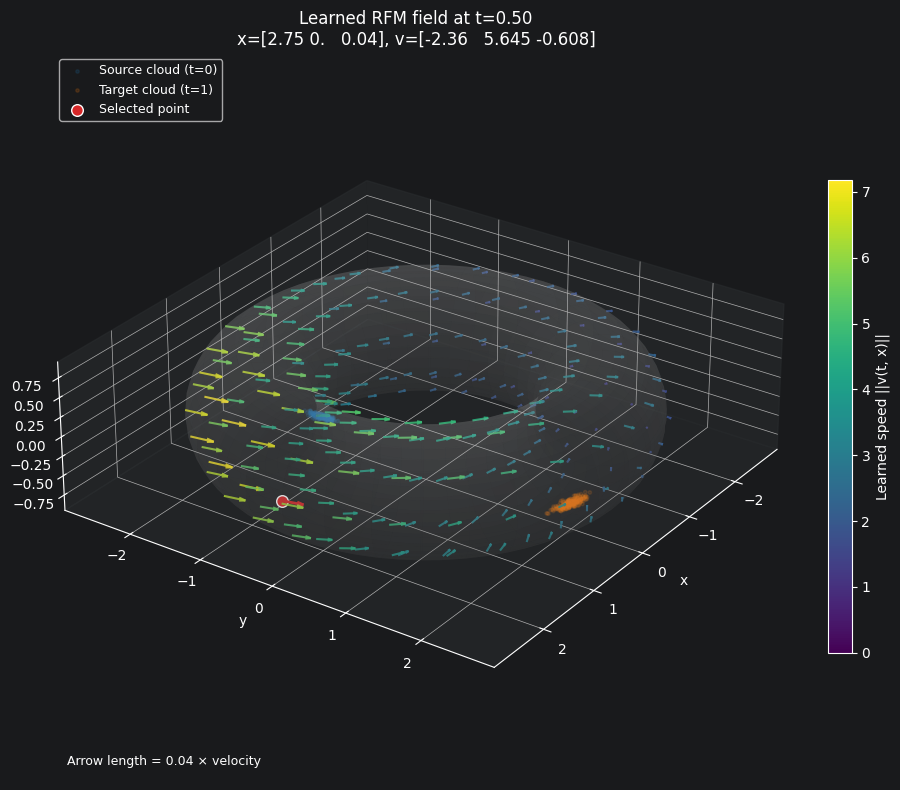

v(t=0.5, x=[2.7490627765655518, 0.0, 0.03748437762260437]) = [-2.3597946   5.64469    -0.60808986]
Speed: 6.148246


In [53]:
# Change these two values and rerun this cell.
rfm_query_point = angles_to_torus(np.array([0.0, 0.05])).astype(np.float32)
rfm_field_time = 0.5


def plot_rfm_learned_field(point, time, grid_size=27, arrow_dt=0.04):
    """Plot the trained instantaneous velocity and highlight v(time, point)."""
    if not rfm_cf.solver.is_trained:
        raise ValueError("Run the RFM training cell first.")
    point = np.asarray(point, dtype=np.float32)
    if point.shape != (3,) or not np.all(np.isfinite(point)):
        raise ValueError("point must contain three finite coordinates.")
    if not np.isfinite(time) or not 0.0 <= time <= 1.0:
        raise ValueError("time must be between 0 and 1.")
    if grid_size < 3 or arrow_dt <= 0:
        raise ValueError("grid_size must be at least 3 and arrow_dt must be positive.")

    grid_u, grid_v = np.meshgrid(
        np.linspace(0.0, 2.0 * np.pi, grid_size, endpoint=False),
        np.linspace(0.0, 2.0 * np.pi, max(3, grid_size // 3), endpoint=False),
    )
    grid = angles_to_torus(np.column_stack((grid_u.ravel(), grid_v.ravel()))).astype(np.float32)
    query_points = jnp.asarray(np.vstack((grid, point[None])))

    # Same condition, inference state, and deterministic encoder noise as prediction.
    condition = {
        key: jnp.asarray(values[:1])
        for key, values in rfm_cf.train_data.condition_data.items()
    }
    state = rfm_cf.solver.vf_state_inference
    encoder_noise = jnp.zeros((1, rfm_cf.solver.vf.condition_embedding_dim))

    @jax.jit
    def evaluate_field(positions, query_time):
        times = jnp.full((positions.shape[0], 1), query_time, dtype=positions.dtype)
        return state.apply_fn(
            {"params": state.params},
            times,
            positions,
            condition,
            encoder_noise=encoder_noise,
            train=False,
        )[0]

    velocities = np.asarray(evaluate_field(query_points, jnp.asarray(time)))
    if not np.all(np.isfinite(velocities)):
        raise ValueError("The learned field contains non-finite velocities.")
    grid_velocities, point_velocity = velocities[:-1], velocities[-1]
    speeds = np.linalg.norm(grid_velocities, axis=1)
    color_norm = Normalize(0.0, max(float(speeds.max()), 1e-6))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(*rfm_source.T, s=6, alpha=0.15, color="tab:blue", label="Source cloud (t=0)")
    ax.scatter(*rfm_target.T, s=6, alpha=0.15, color="tab:orange", label="Target cloud (t=1)")
    ax.quiver(
        *grid.T, *(arrow_dt * grid_velocities).T,
        colors=plt.get_cmap("viridis")(color_norm(speeds)),
        length=1.0, normalize=False, arrow_length_ratio=0.3, alpha=0.85,
    )
    fig.colorbar(
        plt.cm.ScalarMappable(norm=color_norm, cmap="viridis"),
        ax=ax, label="Learned speed ||v(t, x)||", shrink=0.65,
    )
    ax.scatter(*point, s=70, color="tab:red", edgecolor="white", zorder=5, label="Selected point")
    ax.quiver(*point, *(arrow_dt * point_velocity),
              length=1.0, normalize=False, color="tab:red", linewidth=2, arrow_length_ratio=0.3)
    arrow_tip = point + arrow_dt * point_velocity
    style_torus(ax, extra_points=np.vstack((point, arrow_tip)))
    ax.set_title(
        f"Learned RFM field at t={time:.2f}" + chr(10)
        + f"x={np.round(point, 2)}, v={np.round(point_velocity, 3)}"
    )
    ax.text2D(0.02, 0.02, f"Arrow length = {arrow_dt:g} × velocity", transform=ax.transAxes, fontsize=9)
    ax.legend(loc="upper left", fontsize=9)
    fig.tight_layout()
    plt.show()
    return fig, ax, point_velocity


rfm_field_fig, rfm_field_ax, rfm_query_velocity = plot_rfm_learned_field(
    rfm_query_point, rfm_field_time
)
print(f"v(t={rfm_field_time}, x={rfm_query_point.tolist()}) = {rfm_query_velocity}")
print(f"Speed: {np.linalg.norm(rfm_query_velocity):.6f}")

## Learned trajectories from new source samples

Draw fresh points from the same truncated angular Gaussian as the source dataset on the torus surface. Change `rfm_n_new_points` or `rfm_trajectory_seed` below to choose a different sample. Each trajectory solves $\dot{x}_t=v_	heta(t,x_t\mid\mathrm{target\ Gaussian})$ from $t=0$ to $t=1$ using the trained inference weights and the standard predictor's Tsit5 solver and tolerances. Saving intermediate states makes the full paths visible.

Circle markers show starting points, crosses mark endpoints, and small arrows indicate travel direction. The tube-radius plot shows when a path leaves the torus. The trajectories use the learned field directly, so departures from the torus are retained.

In [54]:
import diffrax

rfm_n_new_points = 6
rfm_trajectory_seed = 2027
rfm_trajectory_times = np.linspace(0.0, 1.0, 201, dtype=np.float32)

if not rfm_cf.solver.is_trained:
    raise ValueError("Run the RFM training cell first.")
if rfm_n_new_points < 1:
    raise ValueError("rfm_n_new_points must be positive.")

# Fresh draws from the source distribution, independent of the training cloud.
rfm_new_start_points, _ = sample_angular_gaussian_on_torus(
    source_angle_center, angular_std, rfm_n_new_points,
    np.random.default_rng(rfm_trajectory_seed),
)
rfm_new_start_points = rfm_new_start_points.astype(np.float32)
assert np.all(in_torus(rfm_new_start_points))
assert not np.any(np.all(
    rfm_new_start_points[:, None, :] == rfm_source[None, :, :], axis=2
))

rfm_path_condition = {
    key: jnp.asarray(values[:1])
    for key, values in rfm_cf.train_data.condition_data.items()
}
rfm_path_state = rfm_cf.solver.vf_state_inference
rfm_path_encoder_noise = jnp.zeros((1, rfm_cf.solver.vf.condition_embedding_dim))


def rfm_learned_path_velocity(t, position, args):
    params, condition, encoder_noise = args
    return rfm_path_state.apply_fn(
        {"params": params},
        t,
        position,
        condition,
        encoder_noise,
        train=False,
    )[0]


def rfm_integrate_new_point(params, start, condition, encoder_noise):
    solution = diffrax.diffeqsolve(
        diffrax.ODETerm(rfm_learned_path_velocity),
        solver=diffrax.Tsit5(),
        t0=0.0,
        t1=1.0,
        dt0=None,
        y0=start,
        args=(params, condition, encoder_noise),
        stepsize_controller=diffrax.PIDController(rtol=1e-5, atol=1e-5),
        saveat=diffrax.SaveAt(ts=jnp.asarray(rfm_trajectory_times)),
    )
    return solution.ys, solution.stats["num_steps"]


# Shape: (number of new points, number of saved times, 3).
rfm_new_trajectories, rfm_new_solver_steps = jax.jit(
    jax.vmap(rfm_integrate_new_point, in_axes=(None, 0, None, None))
)(rfm_path_state.params, jnp.asarray(rfm_new_start_points),
  rfm_path_condition, rfm_path_encoder_noise)
rfm_new_trajectories = np.asarray(rfm_new_trajectories)
assert rfm_new_trajectories.shape == (rfm_n_new_points, len(rfm_trajectory_times), 3)
assert np.all(np.isfinite(rfm_new_trajectories))
np.testing.assert_allclose(rfm_new_trajectories[:, 0], rfm_new_start_points)

# Check that saving the paths gives the same endpoints as standard prediction.
rfm_new_predicted_endpoints = rfm_cf.solver.predict(
    rfm_new_start_points, rfm_path_condition
)
np.testing.assert_allclose(
    rfm_new_trajectories[:, -1], rfm_new_predicted_endpoints, rtol=1e-4, atol=1e-4
)
print(f"Integrated {rfm_n_new_points} new source samples, with {len(rfm_trajectory_times)} saved times each.")
print("Maximum endpoint difference from standard prediction:",
      np.max(np.abs(rfm_new_trajectories[:, -1] - rfm_new_predicted_endpoints)))

Integrated 6 new source samples, with 201 saved times each.
Maximum endpoint difference from standard prediction: 1.1641532e-10


,start_x,start_y,start_z,end_x,end_y,end_z,min_sampled_tube_radius,max_sampled_tube_radius,endpoint_in_torus,all_saved_points_in_torus,adaptive_solver_steps
Path 1,2.002493,0.008884,0.749996,0.922411,2.480283,-0.009675,0.626428,0.75,False,False,910
Path 2,2.063417,-0.066396,0.747223,0.959660,2.448045,0.006339,0.618513,0.75,False,False,918
Path 3,2.012092,0.097611,0.749861,0.934931,2.518852,-0.064610,0.636586,0.75,False,False,918
Path 4,2.026417,-0.015787,0.749532,0.935722,2.469052,-0.003533,0.624420,0.75,False,False,902
Path 5,2.030804,-0.047390,0.749344,0.939214,2.453480,0.008097,0.619909,0.75,False,False,910
Path 6,1.996695,-0.005913,0.749993,0.914979,2.474997,0.001421,0.624586,0.75,False,False,913


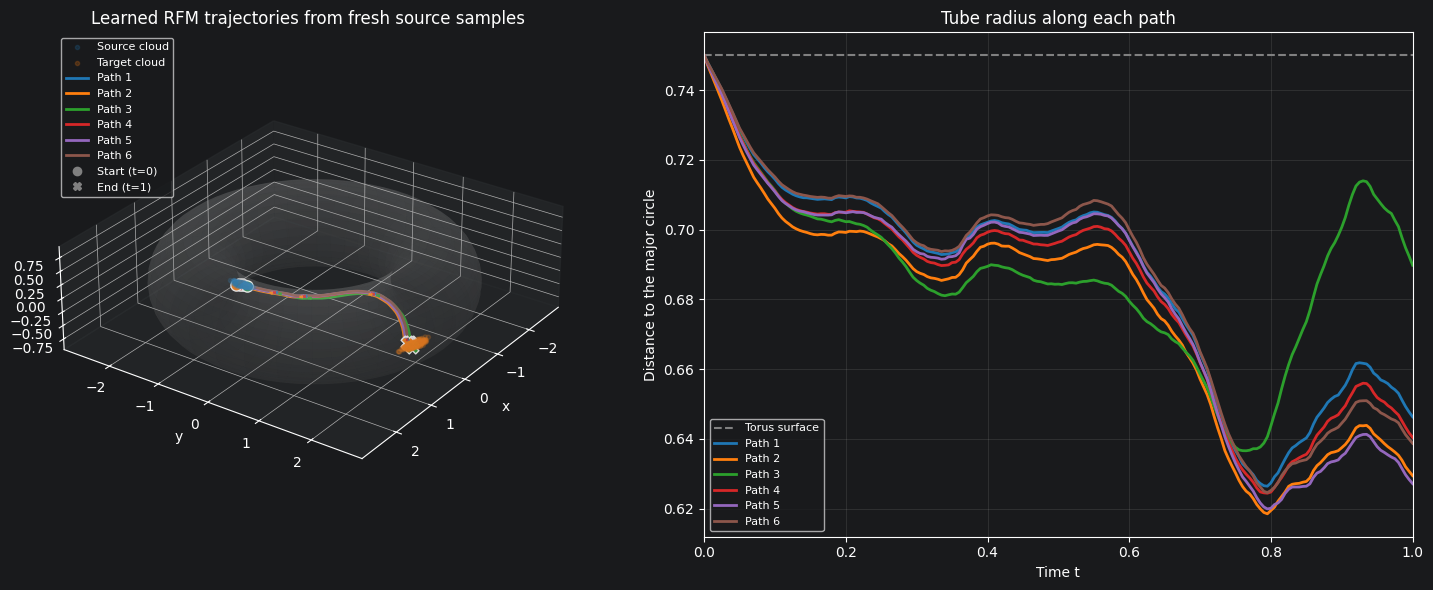

6/6 paths leave the torus surface at a saved time.


In [55]:
from matplotlib.lines import Line2D

rfm_new_path_tube_radii = torus_tube_radius(rfm_new_trajectories)
rfm_new_path_in_torus = np.abs(rfm_new_path_tube_radii - minor_radius) <= 1e-4
rfm_new_path_summary = pd.DataFrame(
    {
        "start_x": rfm_new_start_points[:, 0],
        "start_y": rfm_new_start_points[:, 1],
        "start_z": rfm_new_start_points[:, 2],
        "end_x": rfm_new_trajectories[:, -1, 0],
        "end_y": rfm_new_trajectories[:, -1, 1],
        "end_z": rfm_new_trajectories[:, -1, 2],
        "min_sampled_tube_radius": rfm_new_path_tube_radii.min(axis=1),
        "max_sampled_tube_radius": rfm_new_path_tube_radii.max(axis=1),
        "endpoint_in_torus": rfm_new_path_in_torus[:, -1],
        "all_saved_points_in_torus": rfm_new_path_in_torus.all(axis=1),
        "adaptive_solver_steps": np.asarray(rfm_new_solver_steps),
    },
    index=[f"Path {i + 1}" for i in range(rfm_n_new_points)],
)
display(rfm_new_path_summary)

fig = plt.figure(figsize=(15, 6))
path_ax = fig.add_subplot(121, projection="3d")
radius_ax = fig.add_subplot(122)
path_ax.scatter(*rfm_source.T, s=9, alpha=0.2, color="tab:blue", label="Source cloud")
path_ax.scatter(*rfm_target.T, s=9, alpha=0.2, color="tab:orange", label="Target cloud")
style_torus(path_ax, extra_points=rfm_new_trajectories.reshape(-1, 3))
radius_ax.axhline(minor_radius, color="gray", linestyle="--", label="Torus surface")

rfm_path_colors = plt.get_cmap("tab10")
for path_idx, path in enumerate(rfm_new_trajectories):
    color = rfm_path_colors(path_idx % 10)
    label = f"Path {path_idx + 1}"
    path_ax.plot(*path.T, color=color, linewidth=2, label=label)
    path_ax.scatter(*path[0], s=65, color=color, edgecolor="white", zorder=5)
    path_ax.scatter(*path[-1], marker="X", s=85, color=color, edgecolor="white", zorder=6)
    for time_idx in np.linspace(25, len(path) - 15, 4, dtype=int):
        direction = path[time_idx + 4] - path[time_idx]
        path_ax.quiver(*path[time_idx], *direction, length=1.0, normalize=False,
                       color=color, linewidth=1.8, arrow_length_ratio=0.4)
    radius_ax.plot(rfm_trajectory_times, rfm_new_path_tube_radii[path_idx],
                   color=color, linewidth=2, label=label)

path_ax.set_title("Learned RFM trajectories from fresh source samples")
handles, labels = path_ax.get_legend_handles_labels()
handles.extend([
    Line2D([], [], linestyle="none", marker="o", color="gray", label="Start (t=0)"),
    Line2D([], [], linestyle="none", marker="X", color="gray", label="End (t=1)"),
])
path_ax.legend(handles=handles, loc="upper left", fontsize=8)
radius_ax.set(xlabel="Time t", ylabel="Distance to the major circle", xlim=(0, 1),
              title="Tube radius along each path")
radius_ax.legend(fontsize=8, loc="best")
radius_ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print(f"{np.count_nonzero(~rfm_new_path_in_torus.all(axis=1))}/{rfm_n_new_points}"
      " paths leave the torus surface at a saved time.")

## Euclidean OT and regular Flow Matching comparison

Train a second CellFlow model on the same source and target clouds using the existing `solver="otfm"` implementation. The network configuration and optimizer are copied from the RFM model; batch size, iteration count, initialization seed, time sampler, EMA, OT regularization, and mean cost scaling also match.

The coupling uses **unsquared Euclidean distance in the original three coordinates**:
$$c_{\mathrm{E}}(x,y)=\|x-y\|_2.$$
Regular Flow Matching uses the existing zero-noise constant-noise path:
$$x_t=(1-t)x_0+tx_1,\qquad u_t=x_1-x_0.$$
It uses ambient straight interpolations. The Nyström model, torus projection, RFM interpolation resolution, and RFM velocity clipping are specific to the Riemannian solver and are omitted from the Euclidean model.

Run the RFM training, prediction, and fresh-sample trajectory cells above first. The comparison uses the same fitted clouds for endpoint metrics and exactly the same fresh source points and saved times for path plots. Both prediction solvers use their standard unconstrained Tsit5 integration with tolerances $10^{-5}$. Training losses regress different velocity targets; compare endpoint distribution metrics and surface deviations to assess the models.

,Euclidean coupling diagnostics
coupling_mass,9.999995e-01
max_source_marginal_error,4.656613e-09
max_target_marginal_error,6.519258e-09
OT_mean_euclidean_cost,2.889440e+00
independent_mean_euclidean_cost,2.889449e+00


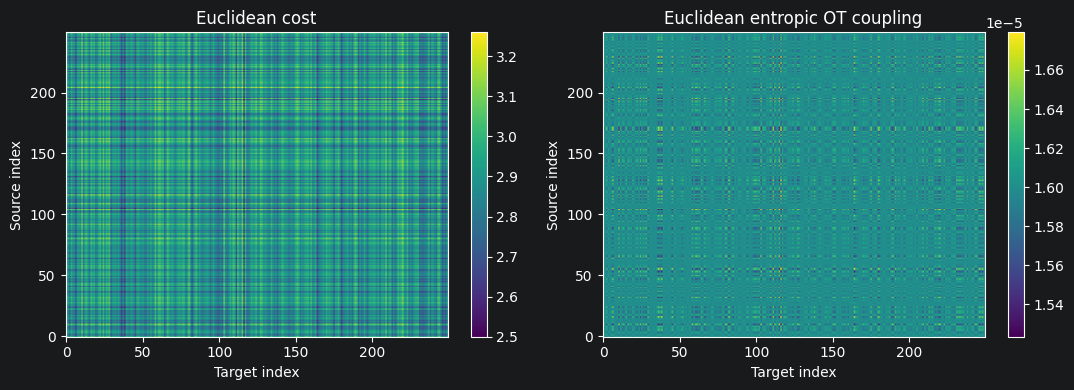

In [56]:
# Euclidean coupling on raw coordinates, with the same OT settings as RFM.
fm_source = rfm_source
fm_target = rfm_target
fm_ot_epsilon = rfm_ot_epsilon
fm_batch_size = rfm_batch_size
fm_num_iterations = rfm_num_iterations
fm_seed = rfm_seed


def match_euclidean(source_batch, target_batch):
    return match_linear(
        jnp.asarray(source_batch),
        jnp.asarray(target_batch),
        cost_fn=costs.Euclidean(),
        epsilon=fm_ot_epsilon,
        scale_cost="mean",
        tau_a=1.0,
        tau_b=1.0,
        threshold=1e-5,
        max_iterations=5000,
    )


fm_match_jit = jax.jit(match_euclidean)
fm_cost_matrix = cdist(fm_source, fm_target)
fm_coupling = np.asarray(fm_match_jit(fm_source, fm_target))
assert fm_coupling.shape == (len(fm_source), len(fm_target))
assert np.all(np.isfinite(fm_coupling)) and np.all(fm_coupling >= 0.0)
np.testing.assert_allclose(fm_coupling.sum(axis=1), 1 / len(fm_source), atol=5e-5)
np.testing.assert_allclose(fm_coupling.sum(axis=0), 1 / len(fm_target), atol=5e-5)
np.testing.assert_allclose(
    np.diag(fm_cost_matrix[:8, :8]),
    np.linalg.norm(fm_source[:8] - fm_target[:8], axis=1),
    rtol=1e-6, atol=1e-6,
)
fm_rectangular_coupling = np.asarray(fm_match_jit(fm_source[7:0:-1], fm_target[2:11]))
assert fm_rectangular_coupling.shape == (7, 9)
assert np.all(np.isfinite(fm_rectangular_coupling))
display(pd.DataFrame({
    "coupling_mass": fm_coupling.sum(),
    "max_source_marginal_error": np.max(np.abs(fm_coupling.sum(axis=1) - 1 / len(fm_source))),
    "max_target_marginal_error": np.max(np.abs(fm_coupling.sum(axis=0) - 1 / len(fm_target))),
    "OT_mean_euclidean_cost": np.sum(fm_coupling * fm_cost_matrix),
    "independent_mean_euclidean_cost": fm_cost_matrix.mean(),
}, index=["Euclidean coupling diagnostics"]).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in [
    (axes[0], fm_cost_matrix, "Euclidean cost"),
    (axes[1], fm_coupling, "Euclidean entropic OT coupling"),
]:
    image = ax.imshow(values, aspect="auto", origin="lower")
    ax.set(xlabel="Target index", ylabel="Source index", title=title)
    fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

In [57]:
from cellflow.solvers import OTFlowMatching

# Copy the fitted RFM model's architecture, including its default settings.
# The optimizer transformation is shared; the new model initializes fresh
# parameters and optimizer state from the same initialization seed.
fm_architecture_names = (
    "condition_mode", "regularization", "condition_embedding_dim",
    "pooling", "pooling_kwargs", "layers_before_pool", "layers_after_pool",
    "cond_output_dropout", "condition_encoder_kwargs",
    "time_freqs", "time_max_period", "time_encoder_dims", "time_encoder_dropout",
    "hidden_dims", "hidden_dropout", "conditioning", "conditioning_kwargs",
    "decoder_dims", "decoder_dropout",
    "layer_norm_before_concatenation", "linear_projection_before_concatenation",
)
fm_architecture_kwargs = {
    name: getattr(rfm_cf.vf, name) for name in fm_architecture_names
}
fm_architecture_kwargs["vf_act_fn"] = rfm_cf.vf.act_fn

fm_cf = CellFlow(rfm_adata.copy(), solver="otfm")
fm_cf.prepare_data(
    sample_rep="X",
    control_key="control",
    perturbation_covariates={"transport": ["target_gaussian"]},
)
fm_cf.prepare_model(
    **fm_architecture_kwargs,
    match_fn=match_euclidean,
    probability_path={"constant_noise": 0.0},
    optimizer=rfm_cf.solver.vf_state.tx,
    solver_kwargs={
        "time_sampler": rfm_cf.solver.time_sampler,
        "ema": rfm_cf.solver.ema,
    },
    seed=fm_seed,
)
assert type(fm_cf.solver) is OTFlowMatching
assert fm_cf.vf == rfm_cf.vf
assert fm_cf.solver.probability_path.sigma == 0.0
assert int(fm_cf.solver.vf_state.step) == 0
np.testing.assert_array_equal(fm_cf.train_data.cell_data, rfm_cf.train_data.cell_data)
for key in rfm_cf.train_data.condition_data:
    np.testing.assert_array_equal(
        fm_cf.train_data.condition_data[key], rfm_cf.train_data.condition_data[key]
    )
fm_probe_batch = TrainSampler(fm_cf.train_data, batch_size=fm_batch_size).sample(
    np.random.default_rng(fm_seed)
)
assert np.all(np.asarray(fm_probe_batch["src_cell_data"])[:, 2] > minor_radius / 2.0)
assert np.all(np.abs(np.asarray(fm_probe_batch["tgt_cell_data"])[:, 2]) < minor_radius / 2.0)
print("Solver:", type(fm_cf.solver).__name__)
print("Architecture matches RFM:", fm_cf.vf == rfm_cf.vf)
print(f"Iterations: {fm_num_iterations}; batch size: {fm_batch_size}; seed: {fm_seed}")
print(f"Unsquared Euclidean OT; relative epsilon: {fm_ot_epsilon}; zero-noise straight path")

[########################################] | 100% Completed | 103.41 ms
[########################################] | 100% Completed | 101.96 ms
Solver: OTFlowMatching
Architecture matches RFM: True
Iterations: 300; batch size: 32; seed: 2026
Unsquared Euclidean OT; relative epsilon: 0.05; zero-noise straight path


In [58]:
fm_training_started = time.perf_counter()
fm_cf.train(
    num_iterations=fm_num_iterations,
    batch_size=fm_batch_size,
    valid_freq=100,
)
fm_training_seconds = time.perf_counter() - fm_training_started
fm_losses = np.asarray(fm_cf.trainer.training_logs["loss"])
assert len(fm_losses) == fm_num_iterations and np.all(np.isfinite(fm_losses))
assert fm_cf.solver.is_trained
assert int(fm_cf.solver.vf_state.step) == fm_num_iterations
print(f"Euclidean FM training finished in {fm_training_seconds:.1f}s")
print(f"Mean loss, first 25: {fm_losses[:25].mean():.5f}; last 25: {fm_losses[-25:].mean():.5f}")

100%|██████████| 300/300 [00:02<00:00, 120.62it/s, loss=0.009]

Euclidean FM training finished in 2.5s
Mean loss, first 25: 0.84253; last 25: 0.00825


[########################################] | 100% Completed | 102.56 ms
[########################################] | 100% Completed | 103.56 ms


,energy_distance_squared,mean_error_to_target,outside_torus_fraction,mean_surface_deviation,p95_surface_deviation
unchanged source,5.541737,2.887709,0.0,2.479553e-08,5.960464e-08
biharmonic RFM,0.112643,0.107828,1.0,1.061902e-01,1.667313e-01
Euclidean FM,0.023256,0.030914,1.0,7.681006e-02,2.003385e-01


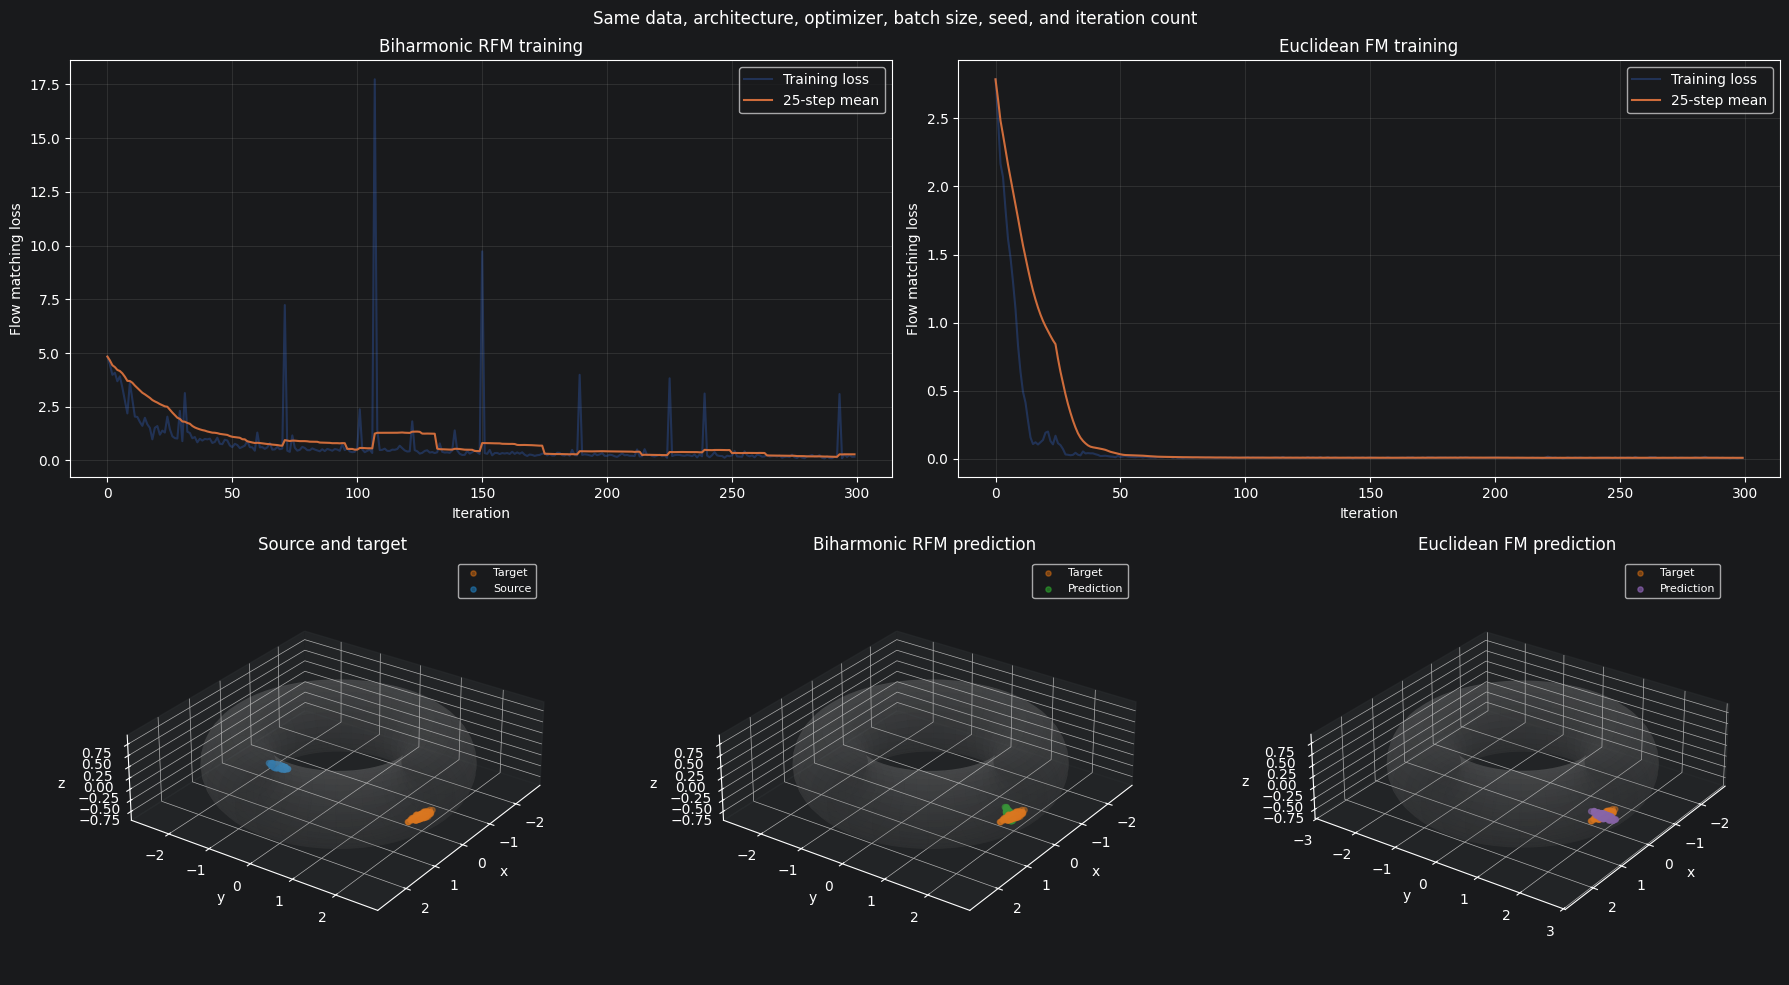

Both predictions use standard unconstrained ODE integration.
Losses fit different velocity targets; endpoint and surface metrics use common units.


In [59]:
# The public prediction API and target condition match the RFM evaluation.
fm_source_adata = rfm_adata[rfm_adata.obs["control"]].copy()
fm_predictions = fm_cf.predict(
    fm_source_adata,
    covariate_data=pd.DataFrame({
        "control": [True], "target_gaussian": [True], "condition": ["target Gaussian"],
    }),
    condition_id_key="condition",
)
fm_predicted = np.asarray(fm_predictions["target Gaussian"])
assert fm_predicted.shape == fm_source.shape
assert np.all(np.isfinite(fm_predicted))


def comparison_distribution_metrics(samples):
    deviation = np.abs(torus_tube_radius(samples) - minor_radius)
    return {
        **rfm_distribution_metrics(samples),
        "mean_surface_deviation": float(deviation.mean()),
        "p95_surface_deviation": float(np.quantile(deviation, 0.95)),
    }


fm_comparison_metrics = pd.DataFrame(
    [comparison_distribution_metrics(samples)
     for samples in (rfm_source, rfm_predicted, fm_predicted)],
    index=["unchanged source", "biharmonic RFM", "Euclidean FM"],
)
display(fm_comparison_metrics)

fig = plt.figure(figsize=(18, 10))
fm_prediction_grid = fig.add_gridspec(2, 6)
loss_axes = [fig.add_subplot(fm_prediction_grid[0, :3]), fig.add_subplot(fm_prediction_grid[0, 3:])]
for ax, losses, title in [
    (loss_axes[0], rfm_losses, "Biharmonic RFM training"),
    (loss_axes[1], fm_losses, "Euclidean FM training"),
]:
    ax.plot(losses, alpha=0.3, label="Training loss")
    ax.plot(pd.Series(losses).rolling(25, min_periods=1).mean(), label="25-step mean")
    ax.set(xlabel="Iteration", ylabel="Flow matching loss", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
for position, samples, title, color in [
    (0, rfm_source, "Source and target", "tab:blue"),
    (1, rfm_predicted, "Biharmonic RFM prediction", "tab:green"),
    (2, fm_predicted, "Euclidean FM prediction", "tab:purple"),
]:
    ax = fig.add_subplot(fm_prediction_grid[1, 2 * position:2 * position + 2], projection="3d")
    ax.scatter(*rfm_target.T, s=14, alpha=0.4, color="tab:orange", label="Target")
    ax.scatter(*samples.T, s=14, alpha=0.6, color=color, label="Source" if position == 0 else "Prediction")
    style_torus(ax, extra_points=samples)
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.suptitle("Same data, architecture, optimizer, batch size, seed, and iteration count")
fig.tight_layout()
plt.show()
print("Both predictions use standard unconstrained ODE integration.")
print("Losses fit different velocity targets; endpoint and surface metrics use common units.")

### Compare the learned fields and fresh-sample paths

Both learned fields below use the same query point, time, torus grid, arrow scale, and speed color scale. They are evaluated directly in $\mathbb{R}^3$.

For the path comparison, reuse `rfm_new_start_points` and `rfm_trajectory_times` exactly. Euclidean FM integrates the existing learned velocity field with the standard Tsit5 solver and tolerances, with no torus projection. Surface deviations are reported for both models, including between their start and endpoint times.

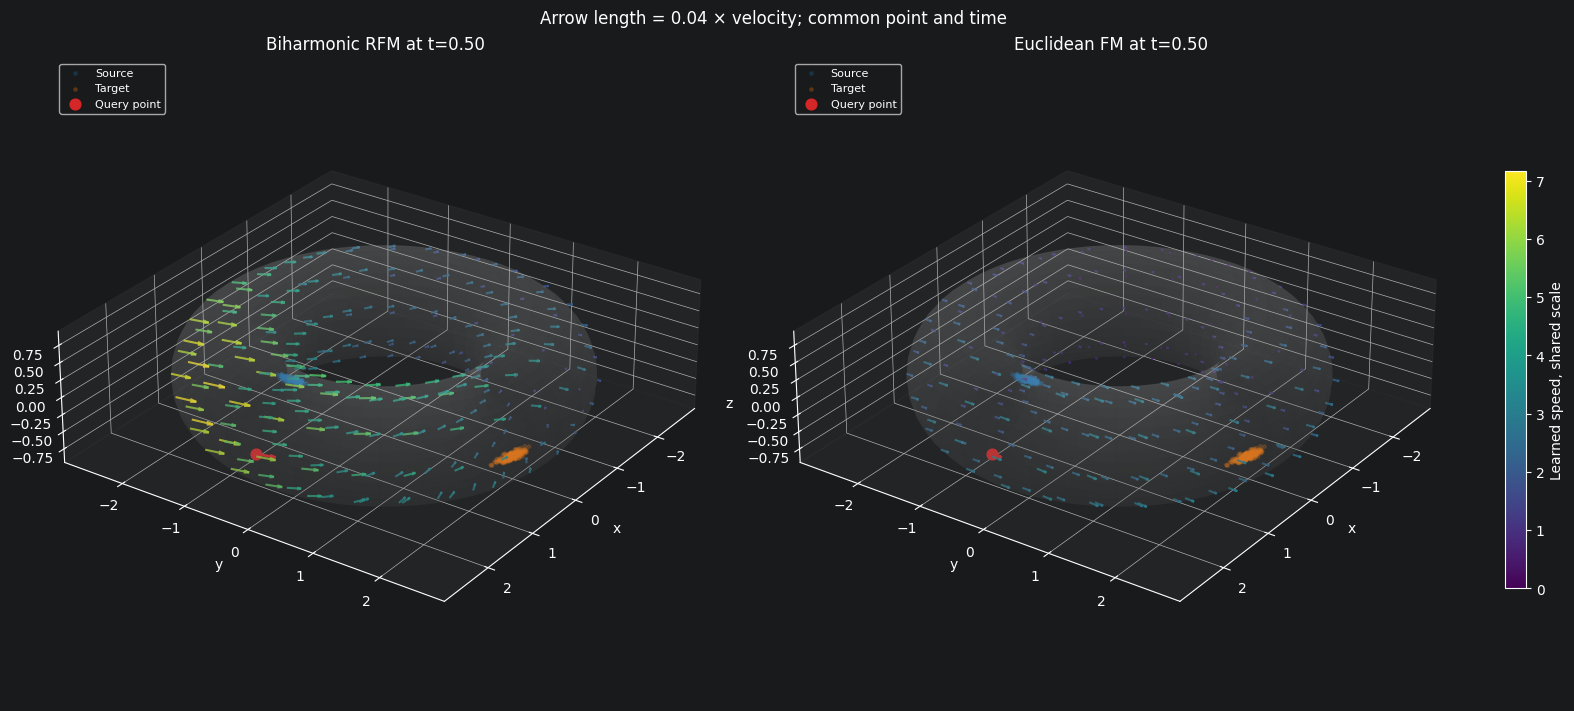

,query_vx,query_vy,query_vz
Biharmonic RFM,-2.359795,5.64469,-0.608090
Euclidean FM,-1.055908,2.88937,-0.854122


In [60]:
fm_query_point = np.asarray(rfm_query_point, dtype=np.float32)
fm_field_time = rfm_field_time
fm_arrow_dt = 0.04
fm_grid_u, fm_grid_v = np.meshgrid(
    np.linspace(0.0, 2.0 * np.pi, 27, endpoint=False),
    np.linspace(0.0, 2.0 * np.pi, 9, endpoint=False),
)
fm_field_grid = angles_to_torus(np.column_stack((
    fm_grid_u.ravel(), fm_grid_v.ravel(),
))).astype(np.float32)
fm_field_queries = jnp.asarray(np.vstack((fm_field_grid, fm_query_point[None])))


def evaluate_comparison_field(model, positions, query_time):
    state = model.solver.vf_state_inference
    condition = {
        key: jnp.asarray(values[:1])
        for key, values in model.train_data.condition_data.items()
    }
    encoder_noise = jnp.zeros((1, model.solver.vf.condition_embedding_dim))

    @jax.jit
    def evaluate(query_positions):
        times = jnp.full((query_positions.shape[0], 1), query_time, dtype=query_positions.dtype)
        return state.apply_fn(
            {"params": state.params}, times, query_positions, condition,
            encoder_noise=encoder_noise, train=False,
        )[0]

    return np.asarray(evaluate(positions))


fm_comparison_fields = {
    "Biharmonic RFM": evaluate_comparison_field(rfm_cf, fm_field_queries, fm_field_time),
    "Euclidean FM": evaluate_comparison_field(fm_cf, fm_field_queries, fm_field_time),
}
assert all(np.all(np.isfinite(values)) for values in fm_comparison_fields.values())
fm_field_color_norm = Normalize(
    0.0, max(float(max(np.linalg.norm(v[:-1], axis=1).max()
                       for v in fm_comparison_fields.values())), 1e-6),
)
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7), subplot_kw={"projection": "3d"}, constrained_layout=True,
)
for ax, (name, velocities) in zip(axes, fm_comparison_fields.items()):
    grid_velocities, point_velocity = velocities[:-1], velocities[-1]
    speeds = np.linalg.norm(grid_velocities, axis=1)
    ax.quiver(
        *fm_field_grid.T, *(fm_arrow_dt * grid_velocities).T,
        colors=plt.get_cmap("viridis")(fm_field_color_norm(speeds)),
        length=1.0, normalize=False, arrow_length_ratio=0.3, alpha=0.8,
    )
    ax.scatter(*rfm_source.T, s=6, alpha=0.2, color="tab:blue", label="Source")
    ax.scatter(*rfm_target.T, s=6, alpha=0.2, color="tab:orange", label="Target")
    ax.scatter(*fm_query_point, s=60, color="tab:red", label="Query point")
    ax.quiver(*fm_query_point, *(fm_arrow_dt * point_velocity),
              color="tab:red", length=1.0, normalize=False, arrow_length_ratio=0.3, linewidth=2)
    style_torus(ax, extra_points=np.vstack((
        fm_query_point, fm_query_point + fm_arrow_dt * point_velocity,
    )))
    ax.set_title(f"{name} at t={fm_field_time:.2f}")
    ax.legend(loc="upper left", fontsize=8)
fig.colorbar(
    plt.cm.ScalarMappable(norm=fm_field_color_norm, cmap="viridis"),
    ax=list(axes), label="Learned speed, shared scale", shrink=0.65,
)
fig.suptitle(f"Arrow length = {fm_arrow_dt:g} × velocity; common point and time")
plt.show()
display(pd.DataFrame(
    [values[-1] for values in fm_comparison_fields.values()],
    index=list(fm_comparison_fields), columns=["query_vx", "query_vy", "query_vz"],
))

In [61]:
# Reuse the same fresh source points and saved times as RFM.
fm_new_start_points = rfm_new_start_points.copy()
fm_trajectory_times = rfm_trajectory_times.copy()
fm_n_new_points = len(fm_new_start_points)
fm_path_condition = {
    key: jnp.asarray(values[:1])
    for key, values in fm_cf.train_data.condition_data.items()
}
fm_path_state = fm_cf.solver.vf_state_inference
fm_path_encoder_noise = jnp.zeros((1, fm_cf.solver.vf.condition_embedding_dim))


def fm_learned_path_velocity(t, position, args):
    params, condition, encoder_noise = args
    return fm_path_state.apply_fn(
        {"params": params}, t, position, condition, encoder_noise, train=False,
    )[0]


def fm_integrate_new_point(params, start, condition, encoder_noise):
    solution = diffrax.diffeqsolve(
        diffrax.ODETerm(fm_learned_path_velocity),
        solver=diffrax.Tsit5(),
        t0=0.0,
        t1=1.0,
        dt0=None,
        y0=start,
        args=(params, condition, encoder_noise),
        stepsize_controller=diffrax.PIDController(rtol=1e-5, atol=1e-5),
        saveat=diffrax.SaveAt(ts=jnp.asarray(fm_trajectory_times)),
    )
    return solution.ys, solution.stats["num_steps"]


fm_new_trajectories, fm_new_solver_steps = jax.jit(
    jax.vmap(fm_integrate_new_point, in_axes=(None, 0, None, None))
)(fm_path_state.params, jnp.asarray(fm_new_start_points),
  fm_path_condition, fm_path_encoder_noise)
fm_new_trajectories = np.asarray(fm_new_trajectories)
assert fm_new_trajectories.shape == rfm_new_trajectories.shape
assert np.all(np.isfinite(fm_new_trajectories))
np.testing.assert_allclose(fm_new_trajectories[:, 0], rfm_new_trajectories[:, 0])
fm_new_predicted_endpoints = fm_cf.solver.predict(fm_new_start_points, fm_path_condition)
np.testing.assert_allclose(
    fm_new_trajectories[:, -1], fm_new_predicted_endpoints, rtol=1e-4, atol=1e-4,
)
print("Same fresh source points and saved times:", fm_new_trajectories.shape)
print("FM maximum endpoint difference from standard prediction:",
      np.max(np.abs(fm_new_trajectories[:, -1] - fm_new_predicted_endpoints)))

Same fresh source points and saved times: (6, 201, 3)
FM maximum endpoint difference from standard prediction: 6.9849193e-10


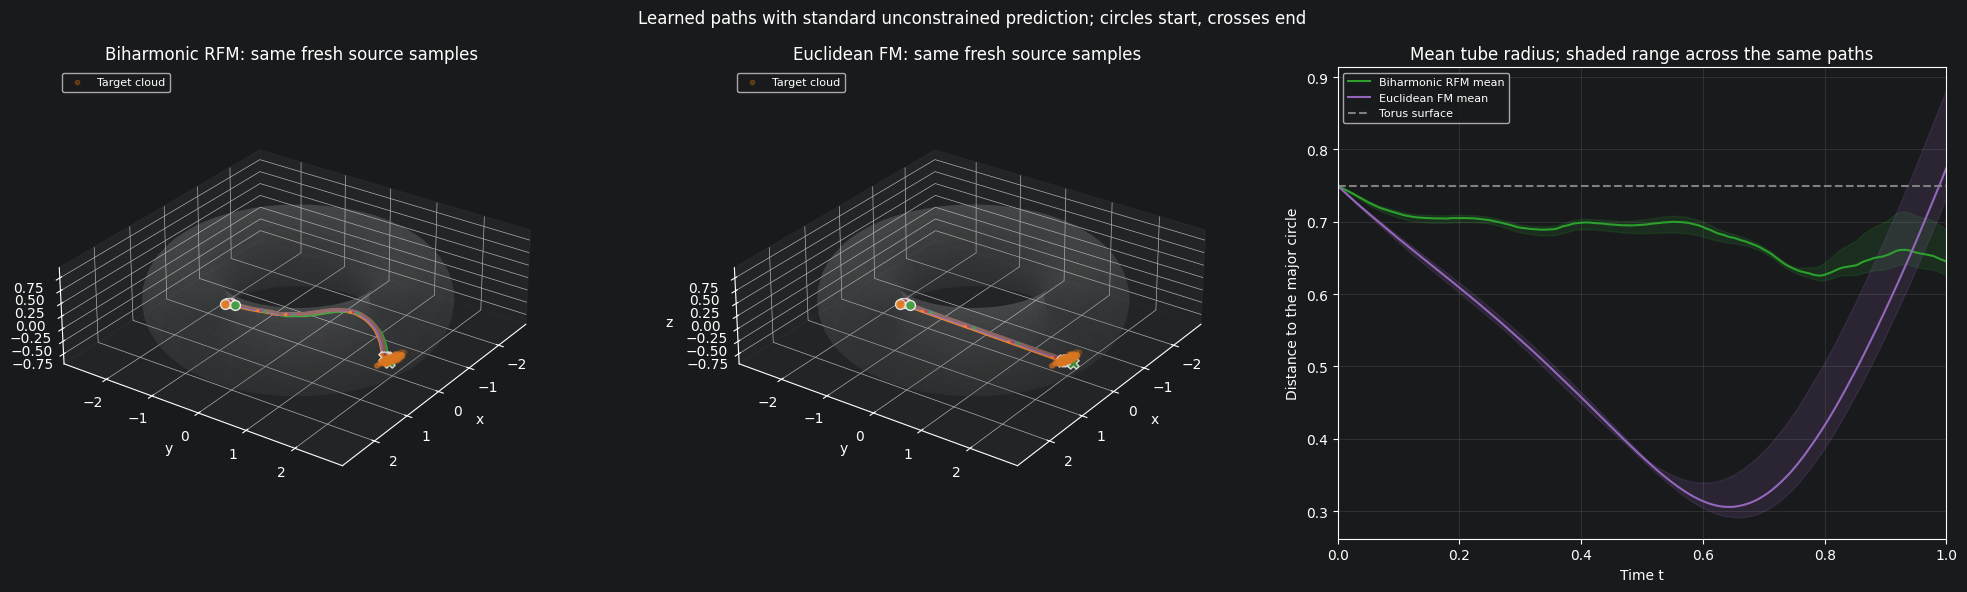

,mean_max_surface_deviation,max_surface_deviation,mean_endpoint_surface_deviation,fraction_saved_points_on_torus
model,,,,
Biharmonic RFM,0.124926,0.131487,0.104687,0.004975
Euclidean FM,0.445923,0.458544,0.034881,0.004975


In [62]:
fm_path_comparison = {
    "Biharmonic RFM": rfm_new_trajectories,
    "Euclidean FM": fm_new_trajectories,
}
fm_path_comparison_rows = []
fig = plt.figure(figsize=(20, 6))
fm_path_axes = [
    fig.add_subplot(131, projection="3d"),
    fig.add_subplot(132, projection="3d"),
]
fm_radius_ax = fig.add_subplot(133)
fm_path_palette = plt.get_cmap("tab10")
for ax, (name, trajectories) in zip(fm_path_axes, fm_path_comparison.items()):
    ax.scatter(*rfm_target.T, color="tab:orange", s=10, alpha=0.25, label="Target cloud")
    style_torus(ax, extra_points=trajectories.reshape(-1, 3))
    for path_index, trajectory in enumerate(trajectories):
        color = fm_path_palette(path_index % 10)
        ax.plot(*trajectory.T, color=color, linewidth=2)
        ax.scatter(*trajectory[0], color=color, s=50, marker="o", edgecolor="white")
        ax.scatter(*trajectory[-1], color=color, s=65, marker="X", edgecolor="white")
        for time_index in np.linspace(25, len(trajectory) - 15, 4, dtype=int):
            direction = trajectory[time_index + 4] - trajectory[time_index]
            ax.quiver(*trajectory[time_index], *direction, color=color,
                      length=1.0, normalize=False, arrow_length_ratio=0.4)
    ax.set_title(name + ": same fresh source samples")
    ax.legend(loc="upper left", fontsize=8)
    tube_radii = torus_tube_radius(trajectories)
    deviation = np.abs(tube_radii - minor_radius)
    model_color = "tab:green" if name == "Biharmonic RFM" else "tab:purple"
    fm_radius_ax.plot(fm_trajectory_times, tube_radii.mean(axis=0),
                      color=model_color, label=name + " mean")
    fm_radius_ax.fill_between(
        fm_trajectory_times, tube_radii.min(axis=0), tube_radii.max(axis=0),
        color=model_color, alpha=0.15,
    )
    fm_path_comparison_rows.append({
        "model": name,
        "mean_max_surface_deviation": deviation.max(axis=1).mean(),
        "max_surface_deviation": deviation.max(),
        "mean_endpoint_surface_deviation": deviation[:, -1].mean(),
        "fraction_saved_points_on_torus": np.mean(deviation <= 1e-4),
    })
fm_radius_ax.axhline(minor_radius, color="gray", linestyle="--", label="Torus surface")
fm_radius_ax.set(xlabel="Time t", ylabel="Distance to the major circle", xlim=(0, 1),
                  title="Mean tube radius; shaded range across the same paths")
fm_radius_ax.legend(fontsize=8)
fm_radius_ax.grid(alpha=0.2)
fig.suptitle("Learned paths with standard unconstrained prediction; circles start, crosses end")
fig.tight_layout()
plt.show()
fm_path_comparison_metrics = pd.DataFrame(fm_path_comparison_rows).set_index("model")
display(fm_path_comparison_metrics)